# Accuracy Is Not Attention

**Abdul Sami** (University of Milano-Bicocca)

This is the analysis notebook for my paper on whether lesion attribution maps (Grad-CAM and friends) of medical image classifiers actually point at the lesion, and whether that changes between correct and misclassified predictions. Everything in the paper is produced here; I don't type numbers in by hand.

Code and data splits: https://github.com/samiwadh/accuracy-is-not-attention
Checkpoints and per-image results: https://www.kaggle.com/datasets/samiwadho/accuracy-is-not-attention-grad-cam-artefacts

**Research questions**
* RQ1: does lesion attribution follow classification accuracy?
* RQ2: within a dataset, does it differ between correct and misclassified images of the same class?
* RQ3: do the answers depend on how the explanation is made and evaluated (target, class mix, lesion size, attribution method, overlap vs. deletion)?

## How I run it

One notebook, several **profiles**. A profile decides which datasets, which backbone and which training settings are used, and every profile writes into its own folder under `outputs/`.

| Profile | What it is | Training needed? |
|---|---|---|
| `v2_main` | all five datasets, ResNet50, baseline fine-tuning (brain MRI is the main result here) | no, checkpoints exist |
| `v3_skin` | stronger skin model (384 px, conv4+conv5 fine-tuned) - main skin result | no |
| `v3_chest` | stronger chest model (conv4+conv5 fine-tuned) - main chest result | no |
| `siim` | SIIM-ACR pneumothorax, pixel masks for the finding that is classified - confirmatory replication | yes, about 1-2 h per seed |
| `densenet_brain` | DenseNet121 on figshare brain MRI - second architecture | yes, about 20-30 min per seed |

Two ways to run:
1. **Everything at once:** restart the kernel and run only the next cell. It goes through the profiles in `RUN_ORDER` one after the other, each with fresh settings.
2. **By hand:** set `PROFILE` in the configuration cell, restart, then *Run All*.

Training is skipped automatically when a finished checkpoint already exists, so re-running only re-does evaluation and the analyses.

## A short history of this notebook

I keep this list so I remember why things are done the way they are.

* **Aug 2026 - first version.** It had three bugs that I only found later: images were divided by 255 *before* `preprocess_input` (which expects 0-255, so the backbone saw almost flat images), the second fine-tuning stage unfroze nothing, and the chest bounding-box images were not kept out of training. It also explained the *predicted* class with a softmax target, which for two classes flips sign between correct and wrong predictions. The 24x chest effect I reported then was an artefact of these problems.
* **Oct 2026 - v2.** Fixed all of the above, patient-level splits, a fixed logit target, three seeds, bootstrap statistics, a centre-prior baseline.
* **Oct 2026 - v3.** After feedback that the skin and chest models were weak, I added stronger configurations for them. Before looking at the results I decided that these would be the main analysis for skin and chest.
* **Oct 2026 - v4.** Equivalence tests, a regression with lesion size, deletion tests, Integrated Gradients and occlusion, a dataset-specific location prior and a duplicate check.
* **Nov 2026 - v5 (this version).** Three outside reviews pointed out real weaknesses, so I changed the analysis:
  * slices/images of the same patient are now resampled together (patient-level bootstrap and clustered errors) instead of being treated as independent;
  * Grad-CAM keeps only positive evidence (ReLU), which could make missed lesions look worse by construction, so I also record the absolute map, the amount of positive and negative evidence and how many maps are empty;
  * brain MRI gets a margin target too, so it is comparable with the binary tasks;
  * lesion size alone (without prediction confidence) is now the main adjustment;
  * deletion uses a second infill (inpainting) and accounts for how much each deletion changes the image and for the starting score;
  * Grad-CAM is compared with the priors image by image, with confidence intervals;
  * a confirmatory replication on SIIM-ACR (analysis plan frozen before training) and a second backbone (DenseNet121).


######## densenet_brain  (started 15:39) ########
TensorFlow 2.10.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
base configuration set; profile = densenet_brain
densenet_brain: outputs/v5_densenet_brain | ['brain_figshare'] | densenet121 224px, batch 16, stage 2 unfreezes conv5
{
 "python": "3.9.25",
 "platform": "Windows-10-10.0.26300-SP0",
 "tensorflow": "2.10.0",
 "numpy": "1.24.3",
 "pandas": "2.3.3",
 "sklearn": "1.6.1",
 "scipy": "1.13.1",
 "opencv": "4.8.0",
 "gpus": [
  "/physical_device:GPU:0"
 ]
}
image readers ok, working size 224
tf.data pipeline and split helper ok
ISIC 2016 loader defined
Kaggle brain and BACH loaders defined
ChestX-ray14 loader defined
figshare loader defined
SIIM-ACR loader defined


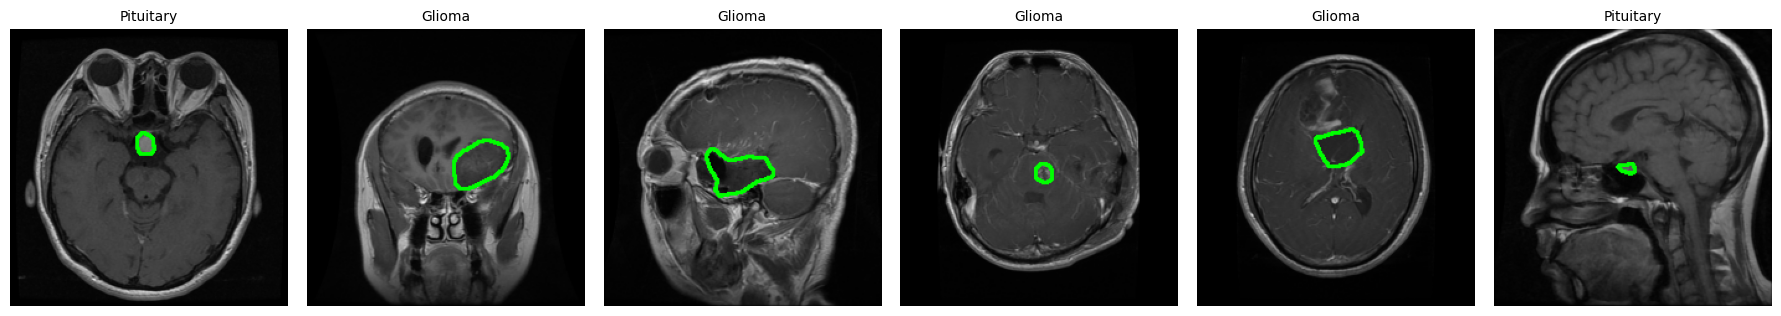

mask loader ready; overlay checks done for ['brain_figshare']
        Domain  Classes  Total  Train  Val  Test  Test_with_GT GT_type  Groups
brain_figshare        3   3064   1984  435   645           645   pixel     233

[brain_figshare]
     3064  slices
      233  patients


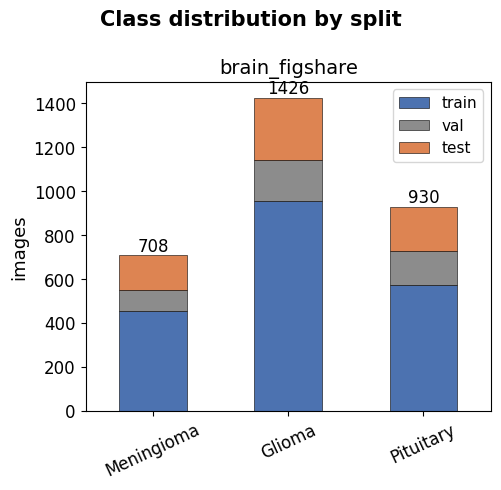

        Domain      Class  train  val  test  total
brain_figshare Meningioma    454   98   156    708
brain_figshare     Glioma    955  186   285   1426
brain_figshare  Pituitary    575  151   204    930
model code ready (densenet121, Grad-CAM layer relu, 14x14 layer conv4_block24_concat)
input-scaling check only runs in v2_main
training functions ready
evaluation functions ready
Grad-CAM functions ready; targets for this profile: ['fixed_true_class']
localisation runner ready
per-run statistics ready
not the SIIM profile - nothing to freeze
Cause: Unable to locate the source code of <function make_dataset.<locals>._parse at 0x000002D61C1BDAF0>. Note that functions defined in certain environments, like the interactive Python shell, do not expose their source code. If that is the case, you should define them in a .py source file. If you are certain the code is graph-compatible, wrap the call using @tf.autograph.experimental.do_not_convert. Original error: could not get source code
To si

,Domain,n_test,seeds,Majority_acc,Chance_bal_acc,accuracy,balanced_accuracy,macro_f1,cohen_kappa,auc,recall_Meningioma,recall_Glioma,recall_Pituitary
0,brain_figshare,645,3,0.442,0.333,0.856 +/- 0.020,0.861 +/- 0.022,0.847 +/- 0.022,0.782 +/- 0.029,0.973 +/- 0.006,0.799 +/- 0.049,0.788 +/- 0.021,0.995 +/- 0.005


,domain,seed,n_C,n_M,patients,mean_C,mean_M,median_C,median_M,delta,delta_ci_patient,p,p_holm,cliffs
0,brain_figshare,42,564,81,47,0.023,0.009,0.011,0.001,-0.013,"[-0.021, -0.004]",0.0,0.0,-0.546
1,brain_figshare,43,539,106,47,0.020,0.013,0.013,0.004,-0.007,"[-0.013, -0.001]",0.0,0.0,-0.335
2,brain_figshare,44,554,89,47,0.023,0.011,0.014,0.001,-0.011,"[-0.018, -0.003]",0.0,0.0,-0.516


brain_figshare  pooled delta -0.010 [-0.017, -0.003]  (645 images, 47 patients), signs - - - -> supported; empty maps C/M 0/2


,domain,energy_C,energy_M,median_C,median_M,pointing_C,pointing_C_ci,pointing_M,centre_prior_energy,centre_prior_pointing,uniform_energy
0,brain_figshare,0.022,0.011,0.013,0.002,0.027,"[0.013, 0.045]",0.011,0.037,0.122,0.017


,domain,seed,true_class,uniform,n_C,n_M,mean_C,mean_M,delta,delta_ci,p
0,brain_figshare,42,Meningioma,0.354,133,23,0.434,0.528,0.094,"[0.04820030641968251, 0.13877286620630477]",0.0
1,brain_figshare,42,Glioma,0.354,227,58,0.328,0.551,0.223,"[0.18555845753263878, 0.2598541674423813]",0.0
2,brain_figshare,42,Pituitary,0.354,204,0,NaN,NaN,NaN,None,NaN
3,brain_figshare,43,Meningioma,0.354,118,38,0.427,0.559,0.132,"[0.07690560690296608, 0.18564852405160853]",0.0
4,brain_figshare,43,Glioma,0.354,218,67,0.362,0.535,0.173,"[0.14731839237679445, 0.1984050200952525]",0.0
5,brain_figshare,43,Pituitary,0.354,203,1,NaN,NaN,NaN,None,NaN
6,brain_figshare,44,Meningioma,0.354,123,33,0.385,0.520,0.135,"[0.08542702274014419, 0.18320891678992984]",0.0
7,brain_figshare,44,Glioma,0.354,229,54,0.315,0.546,0.231,"[0.19442036746676467, 0.26604886920798126]",0.0
8,brain_figshare,44,Pituitary,0.354,202,2,NaN,NaN,NaN,None,NaN


... (16 outputs left out)

C:\Users\lenovo\anaconda3\envs\research\lib\site-packages\numpy\lib\nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,domain,method,empty_maps,energy_correct,energy_misclassified,pointing_correct,median_rho_vs_gradcam,minus_centre_prior_correct,minus_centre_prior_ci95,energy_in_gt_M_minus_C,...,energy_in_gt_cliffs_ci90,energy_in_gt_verdict,enrichment_M_minus_C,enrichment_ci95,enrichment_seed_signs,enrichment_rule,enrichment_cliffs_ci90,enrichment_verdict,minus_gradcam_all,minus_gradcam_ci95
0,brain_figshare,gradcam,2,0.022,0.011,0.027,NaN,-0.013,"[-0.018, -0.01]",-0.010,...,"[-0.584, -0.314]",different,-0.837,"[-1.059, -0.567]",- - -,supported,"[-0.729, -0.503]",different,NaN,NaN
1,brain_figshare,integrated_gradients,0,0.038,0.050,0.159,-0.032,0.003,"[-0.002, 0.007]",0.012,...,"[0.132, 0.409]",different,0.111,"[-0.514, 0.643]",+ + +,not supported,"[-0.181, 0.274]",inconclusive,0.019,"[0.014, 0.025]"
2,brain_figshare,integrated_gradients_abs,0,0.038,0.049,0.183,-0.039,0.003,"[-0.002, 0.007]",0.011,...,"[0.106, 0.387]",different,-0.004,"[-0.595, 0.504]",+ - +,not supported,"[-0.219, 0.225]",inconclusive,0.019,"[0.014, 0.025]"
3,brain_figshare,occlusion,0,0.022,0.029,0.040,0.385,-0.013,"[-0.019, -0.008]",0.007,...,"[-0.079, 0.24]",inconclusive,-0.150,"[-0.521, 0.193]",- - -,not supported,"[-0.232, 0.049]",inconclusive,0.003,"[-0.001, 0.006]"


'no dataset without patient IDs in this profile'

chest_xray not in this profile


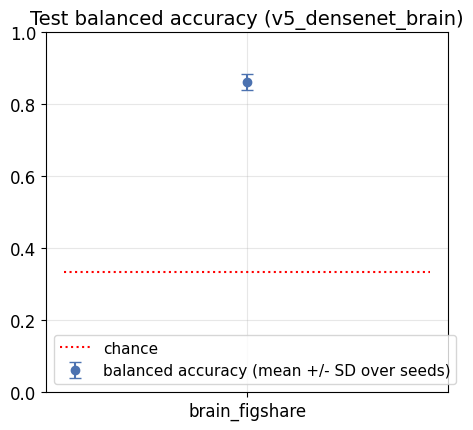

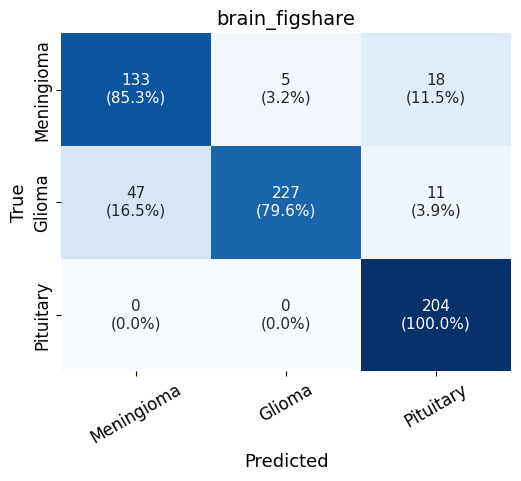

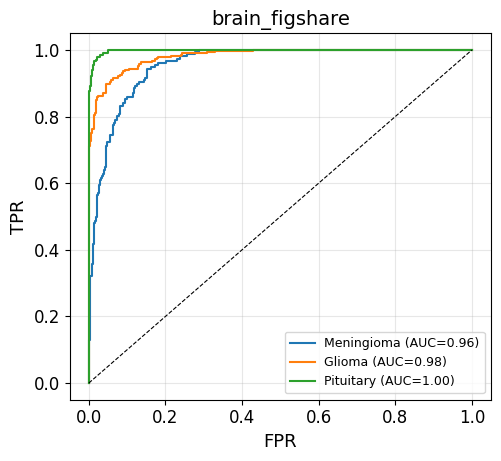

classification figures saved


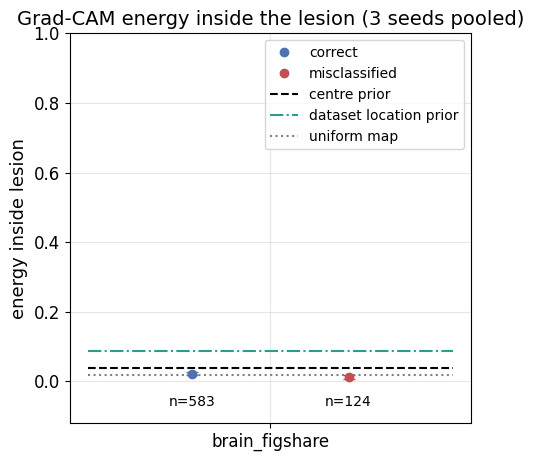

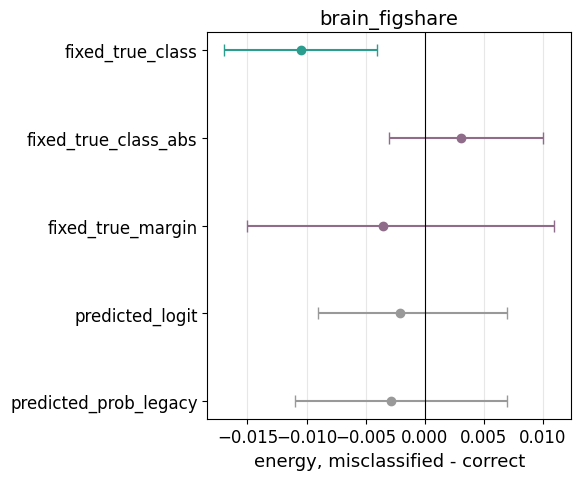

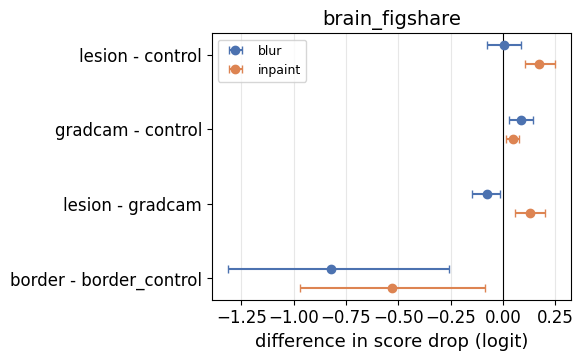

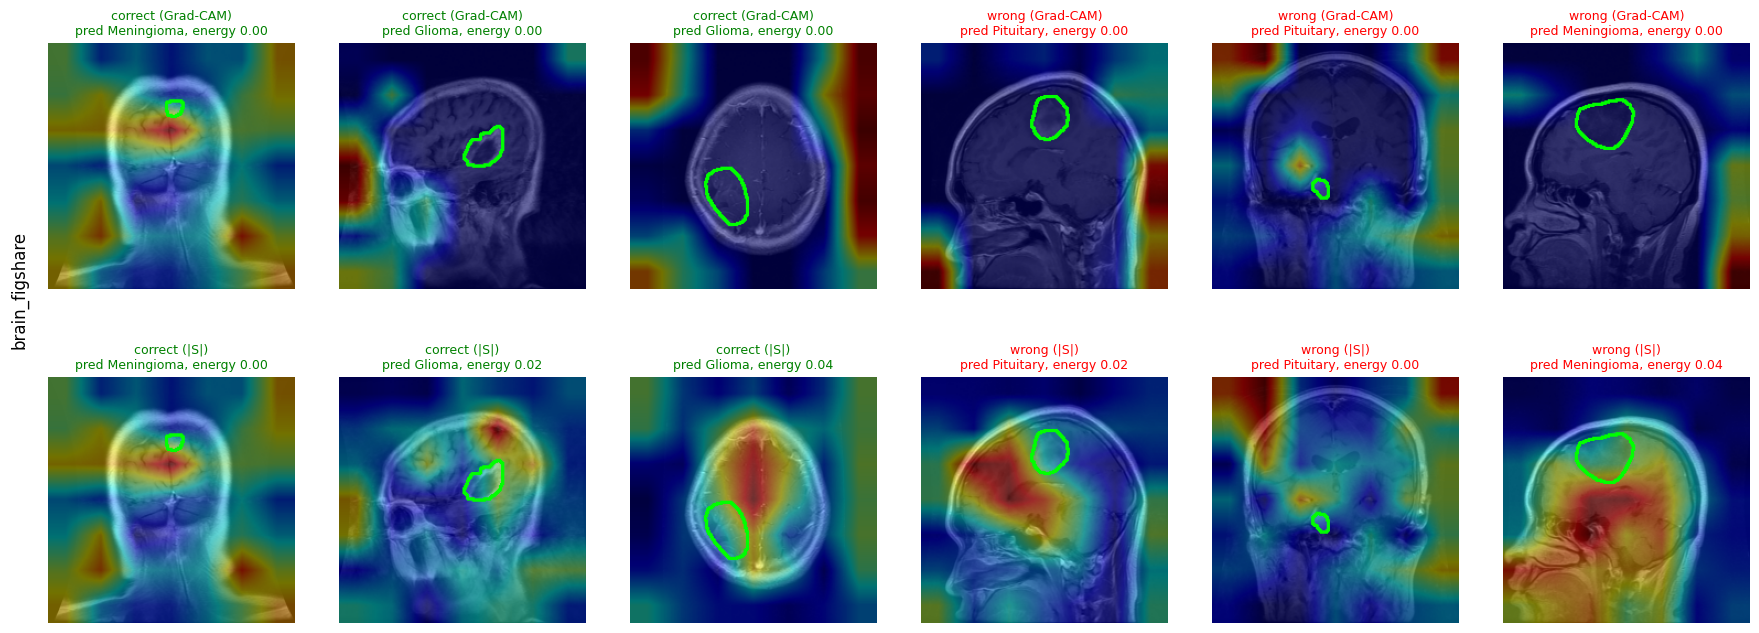


finished densenet_brain; everything is in outputs/v5_densenet_brain
######## densenet_brain finished in 378.9 min ########
table_classification               9 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_primary_per_seed            21 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_baselines_pointing           7 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_border_by_class             39 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_size_check                 117 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_sanity_check                45 rows from ['v2_corrected', 'v3_strong_chest', 'v3_strong_skin', 'v5_densenet_brain', 'v5_siim']
table_methods_layers_pooled       44 rows from ['v2_corrected', 'v3_strong_che

In [3]:
# Run several profiles in a row (option 1 above).
# Each profile gets a clean namespace, so settings of one run (e.g. 384 px skin images) cannot leak into the next.
# I first tried to do this with nbconvert in a separate process, but on my Windows machine that crashed with an
# SSL certificate error before anything ran, so now everything stays inside this kernel.
import os, gc, json, time, traceback
import tensorflow as tf
from IPython.display import display

NB_PATH   = "Accuracy_Is_Not_Attention_v5.ipynb"
RUN_ORDER = ["densenet_brain"]       # add "siim" and "densenet_brain" once their data is ready
STEPS     = ["setup", "data", "model", "train", "results", "robustness", "review", "figures"]
# "robustness" (sanity check, Grad-CAM++) is slow for v2_main; drop it from STEPS if it already ran

with open(NB_PATH, encoding="utf-8") as f:
    all_cells = [c for c in json.load(f)["cells"] if c["cell_type"] == "code"]

def cells_for(steps):
    return ["".join(c["source"]) for c in all_cells if c.get("metadata", {}).get("tags", [None])[0] in steps]

for profile in RUN_ORDER:
    os.environ["AIA_PROFILE"] = profile
    ns = {"__name__": "__main__", "display": display}
    t0 = time.time()
    print(f"\n######## {profile}  (started {time.strftime('%H:%M')}) ########", flush=True)
    try:
        for src in cells_for(STEPS):
            exec(compile(src, f"<{profile}>", "exec"), ns)
    except Exception:
        traceback.print_exc()
        print(f"\nStopped in profile {profile}. The traceback above shows the failing cell.")
        break
    finally:
        tf.keras.backend.clear_session(); gc.collect()
    print(f"######## {profile} finished in {(time.time() - t0) / 60:.1f} min ########", flush=True)
else:
    for src in cells_for(["combine"]):        # one table per analysis over all runs
        exec(compile(src, "<combine>", "exec"), ns)

---
# 1. Setup

In [1]:
import os, sys, json, random, hashlib, platform, time, warnings, glob
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import sklearn
import scipy
from scipy import stats as sps
from scipy.stats import spearmanr
import tensorflow as tf
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)
try:
    display
except NameError:
    display = print

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.10.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Configuration

`PROJECT_DIR` is the only path to edit. The profile comes from the launcher cell, or from the default here when I run the notebook by hand.

In [27]:
PROJECT_DIR = r"D:\01 Research work\Papar\0 Project\1 Cross-Domain Explanation Degradation Study\Source code"
BASE_DIR    = os.path.join(PROJECT_DIR, "Dataset")

PROFILE = os.environ.get("AIA_PROFILE", "v2_main")    # v2_main | v3_skin | v3_chest | siim | densenet_brain

# ImageNet weights. ResNet50 comes from a local file (downloading from Keras failed on my machine once).
# For DenseNet121 the notebook first looks for the local file and otherwise lets Keras download it.
WEIGHT_FILES = {
    "resnet50":    os.path.join(PROJECT_DIR, "resnet50_weights.h5"),
    "densenet121": os.path.join(PROJECT_DIR, "densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5"),
}

BASE_CFG = dict(
    backbone="resnet50",
    img_size=224, batch_size=16,
    epochs_stage1=10, epochs_stage2=20,
    lr_stage1=1e-4, lr_stage2=1e-5,
    adam=dict(beta_1=0.9, beta_2=0.999, epsilon=1e-7),
    finetune_stage="conv5",          # which backbone stage is unfrozen in stage 2 (conv5, or conv4 = conv4+conv5)
    finetune_batchnorm=False,        # BN statistics stay frozen, batches are small
    dropout=0.4,
    early_stop_patience=6, lr_plateau_factor=0.3, lr_plateau_patience=3, min_lr=1e-7,
    checkpoint_monitor="val_loss",   # the same selection rule for every dataset
    use_class_weights=True,          # "balanced", from the training labels only
    augmentation=dict(hflip=True, vflip=False, rotation_factor=0.05, zoom=0.10, contrast=0.10),
    val_fraction=0.20, test_fraction=0.20,
    cam_thresholds=[0.3, 0.4, 0.5, 0.6, 0.7],
    primary_metric="energy_in_gt",   # threshold-free, fixed before the first results
    n_bootstrap=10000, n_permutations=10000, n_bootstrap_cls=2000,
    deterministic_ops=False,
)
print("base configuration set; profile =", PROFILE)

base configuration set; profile = siim


In [28]:
# Profiles. The v3 settings were fixed before I saw any v3 result; the SIIM profile is frozen in its
# protocol file (section 6) before training starts.
PROFILES = {
    "v2_main": dict(run_name="v2_corrected",
                    domains=["skin", "brain", "chest_xray", "histopathology", "brain_figshare"], overrides={}),
    "v3_skin": dict(run_name="v3_strong_skin", domains=["skin"],
                    overrides=dict(img_size=384, batch_size=8, epochs_stage2=30, finetune_stage="conv4",
                                   augmentation=dict(hflip=True, vflip=True, rotation_factor=0.5,
                                                     zoom=0.10, contrast=0.10))),
    "v3_chest": dict(run_name="v3_strong_chest", domains=["chest_xray"],
                     overrides=dict(epochs_stage2=30, finetune_stage="conv4")),
    "siim": dict(run_name="v5_siim", domains=["siim"],
                 overrides=dict(epochs_stage2=30, finetune_stage="conv4")),
    "densenet_brain": dict(run_name="v5_densenet_brain", domains=["brain_figshare"],
                           overrides=dict(backbone="densenet121")),
}

P          = PROFILES[PROFILE]
CFG        = {**BASE_CFG, **P["overrides"]}
RUN_NAME   = P["run_name"]
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs", RUN_NAME)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEEDS, SPLIT_SEED = [42, 43, 44], 42      # seeds change training only; the split is fixed
IMG_SIZE, BATCH_SIZE = CFG["img_size"], CFG["batch_size"]
AUTOTUNE = tf.data.AUTOTUNE
IMG_EXT  = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

print(f"{PROFILE}: outputs/{RUN_NAME} | {P['domains']} | {CFG['backbone']} {IMG_SIZE}px, "
      f"batch {BATCH_SIZE}, stage 2 unfreezes {CFG['finetune_stage']}")

siim: outputs/v5_siim | ['siim'] | resnet50 224px, batch 16, stage 2 unfreezes conv4


In [29]:
def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

def _json_default(o):
    if isinstance(o, np.integer):  return int(o)
    if isinstance(o, np.floating): return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray):  return o.tolist()
    return str(o)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass          # already initialised when the launcher runs several profiles
if CFG["deterministic_ops"]:
    tf.config.experimental.enable_op_determinism()

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), tensorflow=tf.__version__,
           numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
           scipy=scipy.__version__, opencv=cv2.__version__, gpus=[g.name for g in gpus])
save_json({"profile": PROFILE, "env": ENV, "cfg": CFG, "seeds": SEEDS, "split_seed": SPLIT_SEED},
          os.path.join(OUTPUT_DIR, "run_config.json"))

# bigger fonts, the default ones were unreadable in the PDF
plt.rcParams.update({"font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 11, "figure.titlesize": 15})
print(json.dumps(ENV, indent=1))

{
 "python": "3.9.25",
 "platform": "Windows-10-10.0.26300-SP0",
 "tensorflow": "2.10.0",
 "numpy": "1.24.3",
 "pandas": "2.3.3",
 "sklearn": "1.6.1",
 "scipy": "1.13.1",
 "opencv": "4.8.0",
 "gpus": [
  "/physical_device:GPU:0"
 ]
}


---
# 2. Data

### Reading images
Images stay in the 0-255 range: the Keras `preprocess_input` inside the model does the ImageNet normalisation. (Dividing by 255 first was the main bug of my first version.)

In [30]:
def read_image_rgb(path, size=None):
    """Any image -> float32 RGB, 0-255, size x size. Grey images get three equal channels."""
    size = size or IMG_SIZE
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Cannot read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    interp = cv2.INTER_AREA if max(img.shape[:2]) > size else cv2.INTER_LINEAR
    return cv2.resize(img, (size, size), interpolation=interp).astype(np.float32)

def resize_mask(mask, size=None):
    size = size or IMG_SIZE
    return (cv2.resize(np.asarray(mask).astype(np.uint8), (size, size),
                       interpolation=cv2.INTER_NEAREST) > 0).astype(np.uint8)

def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def dhash(path, hash_size=8):
    """64-bit perceptual difference hash, used for the duplicate checks."""
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None:
        return None
    g = cv2.resize(g, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    return "".join("1" if b else "0" for b in (g[:, 1:] > g[:, :-1]).flatten())

print("image readers ok, working size", IMG_SIZE)

image readers ok, working size 224


In [31]:
def build_augmenter(seed):
    a = CFG["augmentation"]
    if a.get("hflip") and a.get("vflip"):
        flip = [tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=seed)]
    elif a.get("hflip"):
        flip = [tf.keras.layers.RandomFlip("horizontal", seed=seed)]
    else:
        flip = []
    return tf.keras.Sequential(flip + [tf.keras.layers.RandomRotation(a["rotation_factor"], seed=seed),
                                       tf.keras.layers.RandomZoom(a["zoom"], seed=seed),
                                       tf.keras.layers.RandomContrast(a["contrast"], seed=seed)],
                               name="augmentation")

def make_dataset(paths, labels, n_classes, training=False, seed=0, augmenter=None):
    paths = np.asarray(paths, dtype=str)
    y = tf.keras.utils.to_categorical(np.asarray(labels, dtype=int), n_classes).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, y))
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    size = IMG_SIZE        # passed explicitly: with a default argument the 384 px skin run crashed once
    def _parse(p, l):
        img = tf.numpy_function(lambda q: read_image_rgb(q.decode("utf-8"), size), [p], tf.float32)
        img.set_shape((size, size, 3))
        return img, l
    ds = ds.map(_parse, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    if training and augmenter is not None:
        ds = ds.map(lambda x, l: (augmenter(x, training=True), l), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

EXCLUSIONS = {}      # what was removed from each dataset and why (saved with Table 1)

def stratified_split(df, frac, seed, group_col=None):
    """Hold out about `frac` of the rows, stratified by label. With group_col, a patient never sits on both sides."""
    if group_col is None:
        a, b = train_test_split(df.index.values, test_size=frac, stratify=df["label"].values, random_state=seed)
        return a, b
    sgkf = StratifiedGroupKFold(n_splits=max(2, int(round(1.0 / frac))), shuffle=True, random_state=seed)
    a, b = next(sgkf.split(np.zeros(len(df)), df["label"].values, groups=df[group_col].values))
    return df.index.values[a], df.index.values[b]

print("tf.data pipeline and split helper ok")

tf.data pipeline and split helper ok


### Dataset loaders

Each loader returns a manifest: one row per image with `path`, `label`, `group` (patient where it is known, otherwise the image itself), `split`, and the localisation ground truth if there is one.

In [32]:
def _read_isic_labels(csv_path):
    raw = pd.read_csv(csv_path, header=None, dtype=str).iloc[:, :2]
    raw.columns = ["image_id", "raw_label"]
    raw["image_id"] = raw["image_id"].astype(str).str.strip()
    raw = raw[raw["image_id"].str.upper().str.startswith("ISIC_")]      # skips a header row if the file has one
    to_label = {"benign": 0, "0": 0, "0.0": 0, "malignant": 1, "1": 1, "1.0": 1}
    raw["label"] = raw["raw_label"].str.strip().str.lower().map(to_label)
    if raw["label"].isna().any():
        raise ValueError(f"unknown ISIC label in {csv_path}: {raw.loc[raw['label'].isna(), 'raw_label'].unique()}")
    return raw[["image_id", "label"]].astype({"label": int}).reset_index(drop=True)

def load_skin():
    root = os.path.join(BASE_DIR, "skin")
    spec = {"train": ("Train", "ISBI2016_ISIC_Part3B_Training_Data",
                      "ISBI2016_ISIC_Part3B_Training_GroundTruth.csv", "ISBI2016_ISIC_Part1_Training_GroundTruth"),
            "test":  ("Test", "ISBI2016_ISIC_Part3B_Test_Data",
                      "ISBI2016_ISIC_Part3B_Test_GroundTruth.csv", "ISBI2016_ISIC_Part1_Test_GroundTruth")}
    frames, excl = [], []
    for official, (sub, img_dir, csv_name, mask_dir) in spec.items():
        lab = _read_isic_labels(os.path.join(root, sub, csv_name))
        lab["path"] = [os.path.join(root, sub, img_dir, i + ".jpg") for i in lab.image_id]
        lab["gt_ref"] = [os.path.join(root, sub, mask_dir, i + "_Segmentation.png") for i in lab.image_id]
        missing = ~lab["path"].map(os.path.exists)
        excl.append((f"{official}: in the CSV but no image file", int(missing.sum())))
        lab = lab[~missing].copy()
        has_mask = lab["gt_ref"].map(os.path.exists)
        excl.append((f"{official}: no segmentation mask (classification only)", int((~has_mask).sum())))
        lab["gt_type"] = np.where(has_mask, "pixel", "none")
        lab.loc[~has_mask, "gt_ref"] = ""
        lab["official"] = official
        frames.append(lab)
    df = pd.concat(frames, ignore_index=True)
    df["group"] = df["image_id"]                       # ISIC 2016 has no patient IDs
    df["split"] = np.where(df["official"] == "test", "test", "train")
    _, val_idx = stratified_split(df[df["official"] == "train"], CFG["val_fraction"], SPLIT_SEED)
    df.loc[val_idx, "split"] = "val"
    EXCLUSIONS["skin"] = excl
    return dict(name="skin", manifest=df, class_names=["Benign", "Malignant"], positive_class=1)

print("ISIC 2016 loader defined")

ISIC 2016 loader defined


In [33]:
def load_brain():
    """Kaggle brain tumour MRI (Nickparvar). Classification only, no masks."""
    root = os.path.join(BASE_DIR, "brain")
    tr_dir, te_dir = os.path.join(root, "Training"), os.path.join(root, "Testing")
    class_names = sorted(d for d in os.listdir(tr_dir) if os.path.isdir(os.path.join(tr_dir, d)))
    assert class_names == sorted(d for d in os.listdir(te_dir) if os.path.isdir(os.path.join(te_dir, d)))
    rows = [(os.path.join(d, c, f), f"{official}/{c}/{f}", k, official)
            for official, d in (("train", tr_dir), ("test", te_dir))
            for k, c in enumerate(class_names)
            for f in sorted(os.listdir(os.path.join(d, c))) if f.lower().endswith(IMG_EXT)]
    df = pd.DataFrame(rows, columns=["path", "image_id", "label", "official"])
    excl = [("files found", len(df))]
    df["md5"] = [md5_file(p) for p in df["path"]]
    n_lab = df.groupby("md5")["label"].nunique()
    conflict = df["md5"].isin(set(n_lab[n_lab > 1].index))
    excl.append(("identical files with different labels (removed)", int(conflict.sum())))
    df = df[~conflict]
    leak = (df["official"] == "test") & df["md5"].isin(set(df.loc[df["official"] == "train", "md5"]))
    excl.append(("test file identical to a training file (removed from test)", int(leak.sum())))
    df = df[~leak]
    dup_test = (df["official"] == "test") & df.duplicated("md5", keep="first")
    excl.append(("duplicate inside the official test set (removed)", int(dup_test.sum())))
    df = df[~dup_test].reset_index(drop=True)
    df["dhash"] = [dhash(p) for p in df["path"]]
    near = (df["official"] == "test") & df["dhash"].isin(set(df.loc[df["official"] == "train", "dhash"]))
    excl.append(("kept, but flagged: test image with a perceptual-hash twin in training", int(near.sum())))
    df["group"] = df["md5"]
    df["gt_type"], df["gt_ref"] = "none", ""
    df["split"] = np.where(df["official"] == "test", "test", "train")
    _, val_idx = stratified_split(df[df["official"] == "train"], CFG["val_fraction"], SPLIT_SEED, group_col="group")
    df.loc[val_idx, "split"] = "val"
    EXCLUSIONS["brain"] = excl
    return dict(name="brain", manifest=df, class_names=class_names, positive_class=None)

def load_histopathology():
    """BACH microscopy photos. Classification only, no patient IDs."""
    root = os.path.join(BASE_DIR, "histopathology", "Photos")
    class_names = ["Normal", "Benign", "InSitu", "Invasive"]
    rows = [(os.path.join(root, c, f), f"{c}/{f}", k) for k, c in enumerate(class_names)
            for f in sorted(os.listdir(os.path.join(root, c))) if f.lower().endswith(IMG_EXT)]
    df = pd.DataFrame(rows, columns=["path", "image_id", "label"])
    excl = [("files found", len(df))]
    df["stem"] = [os.path.splitext(os.path.basename(p))[0].lower() + f"_{l}" for p, l in zip(df["path"], df["label"])]
    dup_stem = df.duplicated("stem", keep="first")          # the same photo as .tif and .png
    excl.append(("same photo stored in two formats (kept one)", int(dup_stem.sum())))
    df = df[~dup_stem]
    readable = np.array([cv2.imread(p, cv2.IMREAD_COLOR) is not None for p in df["path"]])
    excl.append(("unreadable files (removed): " + ", ".join(df.loc[~readable, "image_id"]), int((~readable).sum())))
    df = df[readable].reset_index(drop=True)
    df["md5"] = [md5_file(p) for p in df["path"]]
    df["group"] = df["md5"]
    df["gt_type"], df["gt_ref"] = "none", ""
    trv_idx, _ = stratified_split(df, CFG["test_fraction"], SPLIT_SEED, group_col="group")
    df["split"] = "test"
    tr_idx, val_idx = stratified_split(df.loc[trv_idx], CFG["val_fraction"], SPLIT_SEED, group_col="group")
    df.loc[tr_idx, "split"], df.loc[val_idx, "split"] = "train", "val"
    EXCLUSIONS["histopathology"] = excl
    return dict(name="histopathology", manifest=df, class_names=class_names, positive_class=None)

print("Kaggle brain and BACH loaders defined")

Kaggle brain and BACH loaders defined


In [34]:
def load_chest():
    """ChestX-ray14, only the image archives I downloaded. Split by patient; every patient with a
    bounding box goes to the test set so that no localisation image is ever seen in training."""
    root = os.path.join(BASE_DIR, "chest_xray")
    image_dir = os.path.join(root, "images")
    meta = pd.read_csv(os.path.join(root, "Data_Entry_2017.csv"))
    bbox = pd.read_csv(os.path.join(root, "BBox_List_2017.csv")).rename(columns={"Bbox [x": "x", "h]": "h"})
    available = set(os.listdir(image_dir))
    n_meta = len(meta)
    meta = meta[meta["Image Index"].isin(available)].copy()
    excl = [("rows of Data_Entry_2017.csv whose image I don't have", n_meta - len(meta))]
    df = pd.DataFrame({"path": [os.path.join(image_dir, f) for f in meta["Image Index"]],
                       "image_id": meta["Image Index"].values,
                       "group": meta["Patient ID"].astype(str).values,
                       "label": (meta["Finding Labels"].astype(str).str.strip() != "No Finding").astype(int).values,
                       "finding_labels": meta["Finding Labels"].values})
    n_bbox_all = bbox["Image Index"].nunique()
    bbox = bbox[bbox["Image Index"].isin(set(df["image_id"]))]
    excl.append((f"bounding-box images outside my subset (of {n_bbox_all})", n_bbox_all - bbox["Image Index"].nunique()))
    gt = {i: [dict(x=float(r["x"]), y=float(r["y"]), w=float(r["w"]), h=float(r["h"]), finding=str(r["Finding Label"]))
              for _, r in g.iterrows()] for i, g in bbox.groupby("Image Index")}
    df["gt_type"] = np.where(df["image_id"].isin(set(gt)), "bbox", "none")
    df["gt_ref"] = [json.dumps(gt[i]) if i in gt else "" for i in df["image_id"]]
    df["img_w"], df["img_h"] = np.nan, np.nan
    for idx in df.index[df["gt_type"] == "bbox"]:
        im = cv2.imread(df.at[idx, "path"], cv2.IMREAD_GRAYSCALE)
        df.at[idx, "img_h"], df.at[idx, "img_w"] = im.shape[:2]
    assert not ((df["gt_type"] == "bbox") & (df["label"] == 0)).any(), "a 'No Finding' image has a box"
    forced = df["group"].isin(set(df.loc[df["gt_type"] == "bbox", "group"]))
    df["split"] = ""
    df.loc[forced, "split"] = "test"
    rest = df[~forced]
    n_more = max(0, int(round(CFG["test_fraction"] * len(df))) - int(forced.sum()))
    keep_idx = rest.index.values
    if n_more > 0:
        keep_idx, test_idx = stratified_split(rest, n_more / len(rest), SPLIT_SEED, group_col="group")
        df.loc[test_idx, "split"] = "test"
    tr_idx, val_idx = stratified_split(df.loc[keep_idx], CFG["val_fraction"], SPLIT_SEED, group_col="group")
    df.loc[tr_idx, "split"], df.loc[val_idx, "split"] = "train", "val"
    excl.append((f"images of the {df.loc[forced, 'group'].nunique()} box patients, all put in test", int(forced.sum())))
    EXCLUSIONS["chest_xray"] = excl
    return dict(name="chest_xray", manifest=df, class_names=["Normal", "Disease"], positive_class=1)

print("ChestX-ray14 loader defined")

ChestX-ray14 loader defined


### figshare brain MRI (tumour masks)

The figshare slices come as MATLAB files. I convert them once to PNG images and masks. MATLAB stores arrays column-major, so a careless conversion transposes the masks; the overlay figure below is my check that this did not happen.

In [35]:
FIGSHARE_MAT_DIR = os.path.join(BASE_DIR, "brain_figshare", "mat")
FIGSHARE_PNG_DIR = os.path.join(BASE_DIR, "brain_figshare", "png")
FIGSHARE_INDEX   = os.path.join(FIGSHARE_PNG_DIR, "index.csv")
FIGSHARE_CLASSES = ["Meningioma", "Glioma", "Pituitary"]          # figshare labels 1, 2, 3

def _read_figshare_mat(f):
    try:                                       # v7.3 files are HDF5 and come out transposed
        import h5py
        with h5py.File(f, "r") as h:
            cj = h["cjdata"]
            return (np.array(cj["image"]).T, np.array(cj["tumorMask"]).T, int(np.array(cj["label"]).squeeze()),
                    "".join(chr(int(c)) for c in np.array(cj["PID"]).flatten()))
    except (OSError, ImportError):             # older MATLAB format (or h5py not installed)
        from scipy.io import loadmat
        cj = loadmat(f, squeeze_me=True, struct_as_record=False)["cjdata"]
        return cj.image, cj.tumorMask, int(cj.label), str(cj.PID)

def prepare_brain_figshare():
    os.makedirs(os.path.join(FIGSHARE_PNG_DIR, "images"), exist_ok=True)
    os.makedirs(os.path.join(FIGSHARE_PNG_DIR, "masks"), exist_ok=True)
    files = [f for f in sorted(glob.glob(os.path.join(FIGSHARE_MAT_DIR, "*.mat"))) if not f.lower().endswith("cvind.mat")]
    rows = []
    for f in files:
        img, mask, lab, pid = _read_figshare_mat(f)
        img = img.astype(np.float32)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8) * 255.0
        stem = os.path.splitext(os.path.basename(f))[0]
        ip = os.path.join(FIGSHARE_PNG_DIR, "images", stem + ".png")
        mp = os.path.join(FIGSHARE_PNG_DIR, "masks", stem + "_mask.png")
        cv2.imwrite(ip, img.astype(np.uint8))
        cv2.imwrite(mp, (np.asarray(mask) > 0).astype(np.uint8) * 255)
        rows.append((ip, stem, pid.strip(), lab - 1, mp))
    idx = pd.DataFrame(rows, columns=["path", "image_id", "group", "label", "gt_ref"])
    idx.to_csv(FIGSHARE_INDEX, index=False)
    print(f"{len(idx)} slices from {idx['group'].nunique()} patients (expected 3064 and 233)")

def load_brain_figshare():
    df = pd.read_csv(FIGSHARE_INDEX, dtype={"group": str})
    df["gt_type"] = "pixel"
    trv_idx, _ = stratified_split(df, CFG["test_fraction"], SPLIT_SEED, group_col="group")
    df["split"] = "test"
    tr_idx, val_idx = stratified_split(df.loc[trv_idx], CFG["val_fraction"], SPLIT_SEED, group_col="group")
    df.loc[tr_idx, "split"], df.loc[val_idx, "split"] = "train", "val"
    EXCLUSIONS["brain_figshare"] = [("slices", len(df)), ("patients", df["group"].nunique())]
    return dict(name="brain_figshare", manifest=df, class_names=FIGSHARE_CLASSES, positive_class=None)

print("figshare loader defined")

figshare loader defined


### SIIM-ACR pneumothorax (replication dataset)

I added this dataset because the ChestX-ray14 analysis rests on only 84 images with boxes, and the boxes cover 8 of the 14 findings in the label. In SIIM-ACR the label (pneumothorax yes/no) and the pixel mask describe **the same finding**, and there are about 2,700 positive images with masks.

I use the original competition files: `train-rle.csv` plus the DICOM folder `dicom-images-train` (Kaggle has several copies of it). The DICOM headers contain the patient ID, so the split is by patient. The masks are run-length encoded column by column, which is easy to get wrong, so the overlay figure is again my check. As a fallback, the PNG version (folders `png_images` / `png_masks` and a CSV with `has_pneumo`) also works, but it has no patient IDs.

The first run converts everything to 512 x 512 PNG files once (a few minutes).

In [36]:
SIIM_DIR       = os.path.join(BASE_DIR, "siim")
SIIM_PNG_DIR   = os.path.join(SIIM_DIR, "png512")
SIIM_INDEX     = os.path.join(SIIM_PNG_DIR, "index.csv")

def _rle_to_mask(rle, width, height):
    """SIIM run-length decoding: relative start positions, column-major order."""
    mask = np.zeros(width * height, np.uint8)
    if str(rle).strip() in ("-1", "", "nan"):
        return mask.reshape(width, height).T
    arr = np.asarray([int(v) for v in str(rle).split()])
    pos = 0
    for start, length in zip(arr[0::2], arr[1::2]):
        pos += start
        mask[pos:pos + length] = 1
        pos += length
    return mask.reshape(width, height).T

def _find(pattern):
    hits = glob.glob(os.path.join(SIIM_DIR, "**", pattern), recursive=True)
    return sorted(hits)

def prepare_siim():
    os.makedirs(os.path.join(SIIM_PNG_DIR, "images"), exist_ok=True)
    os.makedirs(os.path.join(SIIM_PNG_DIR, "masks"), exist_ok=True)
    rle_csv = [f for f in _find("*.csv") if "rle" in os.path.basename(f).lower()]
    rows = []
    if rle_csv:                                           # original layout: DICOM + train-rle.csv
        import pydicom
        rle = pd.read_csv(rle_csv[0])
        rle.columns = [c.strip() for c in rle.columns]
        masks_by_id = rle.groupby("ImageId")["EncodedPixels"].apply(list).to_dict()
        dcm_files = {os.path.splitext(os.path.basename(f))[0]: f for f in _find("*.dcm")}
        print(f"found {rle_csv[0]} ({len(masks_by_id)} image IDs) and {len(dcm_files)} DICOM files")
        for k, (iid, rles) in enumerate(masks_by_id.items()):
            if iid not in dcm_files:
                continue
            ds = pydicom.dcmread(dcm_files[iid])
            img = ds.pixel_array.astype(np.float32)
            h, w = img.shape
            m = np.zeros((h, w), np.uint8)
            for r in rles:
                m |= _rle_to_mask(r, w, h)
            ip = os.path.join(SIIM_PNG_DIR, "images", iid + ".png")
            mp = os.path.join(SIIM_PNG_DIR, "masks", iid + "_mask.png")
            cv2.imwrite(ip, cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA).astype(np.uint8))
            cv2.imwrite(mp, cv2.resize(m * 255, (512, 512), interpolation=cv2.INTER_NEAREST))
            rows.append((ip, iid, str(getattr(ds, "PatientID", iid)), int(m.any()), mp, h, w))
            if k % 2000 == 0:
                print(f"  converted {k}/{len(masks_by_id)}")
    else:                                                 # PNG layout: png_images / png_masks + has_pneumo
        csvs = [f for f in _find("*.csv") if "has_pneumo" in pd.read_csv(f, nrows=1).columns]
        assert csvs, f"no train-rle.csv and no CSV with a has_pneumo column under {SIIM_DIR}"
        meta = pd.concat([pd.read_csv(f) for f in csvs], ignore_index=True).drop_duplicates("new_filename")
        img_dir = [d for d in glob.glob(os.path.join(SIIM_DIR, "**", "png_images"), recursive=True)][0]
        msk_dir = [d for d in glob.glob(os.path.join(SIIM_DIR, "**", "png_masks"), recursive=True)][0]
        print(f"PNG layout: {len(meta)} images in {img_dir}")
        for _, r in meta.iterrows():
            src_i, src_m = os.path.join(img_dir, r["new_filename"]), os.path.join(msk_dir, r["new_filename"])
            img = cv2.imread(src_i, cv2.IMREAD_GRAYSCALE)
            m = cv2.imread(src_m, cv2.IMREAD_GRAYSCALE) if os.path.exists(src_m) else np.zeros_like(img)
            iid = os.path.splitext(r["new_filename"])[0]
            ip = os.path.join(SIIM_PNG_DIR, "images", iid + ".png")
            mp = os.path.join(SIIM_PNG_DIR, "masks", iid + "_mask.png")
            cv2.imwrite(ip, cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA))
            cv2.imwrite(mp, cv2.resize(((m > 127) * 255).astype(np.uint8), (512, 512), interpolation=cv2.INTER_NEAREST))
            rows.append((ip, iid, iid, int(r["has_pneumo"]), mp, img.shape[0], img.shape[1]))
    idx = pd.DataFrame(rows, columns=["path", "image_id", "group", "label", "gt_ref", "orig_h", "orig_w"])
    idx.to_csv(SIIM_INDEX, index=False)
    print(f"SIIM: {len(idx)} images, {idx['group'].nunique()} patients, {int(idx['label'].sum())} with pneumothorax")

def load_siim():
    df = pd.read_csv(SIIM_INDEX, dtype={"group": str})
    df["gt_type"] = np.where(df["label"] == 1, "pixel", "none")     # negatives have no lesion to localise
    df.loc[df["gt_type"] == "none", "gt_ref"] = ""
    trv_idx, _ = stratified_split(df, CFG["test_fraction"], SPLIT_SEED, group_col="group")
    df["split"] = "test"
    tr_idx, val_idx = stratified_split(df.loc[trv_idx], CFG["val_fraction"], SPLIT_SEED, group_col="group")
    df.loc[tr_idx, "split"], df.loc[val_idx, "split"] = "train", "val"
    EXCLUSIONS["siim"] = [("images", len(df)), ("patients", df["group"].nunique()), ("with pneumothorax", int(df["label"].sum()))]
    return dict(name="siim", manifest=df, class_names=["No pneumothorax", "Pneumothorax"], positive_class=1)

print("SIIM-ACR loader defined")

SIIM-ACR loader defined


PNG layout: 12047 images in D:\01 Research work\Papar\0 Project\1 Cross-Domain Explanation Degradation Study\Source code\Dataset\siim\siim-acr-pneumothorax\png_images
SIIM: 12047 images, 12047 patients, 2669 with pneumothorax


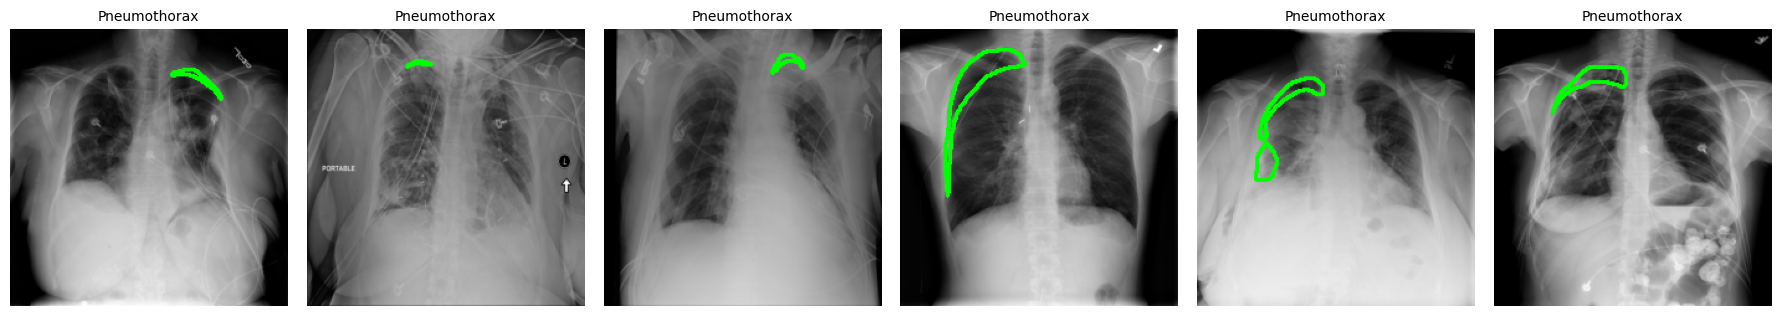

mask loader ready; overlay checks done for ['siim']


In [37]:
def load_gt_mask(row, size=None):
    """Binary size x size mask, or None if the image has no localisation ground truth."""
    size = size or IMG_SIZE
    if row["gt_type"] == "pixel":
        m = cv2.imread(str(row["gt_ref"]), cv2.IMREAD_GRAYSCALE)
        if m is None:
            raise IOError(f"Cannot read mask {row['gt_ref']}")
        return resize_mask(m > 127, size)
    if row["gt_type"] == "bbox":
        sx, sy = size / float(row["img_w"]), size / float(row["img_h"])
        m = np.zeros((size, size), np.uint8)
        for b in json.loads(row["gt_ref"]):
            x0, y0 = int(np.floor(b["x"] * sx)), int(np.floor(b["y"] * sy))
            x1, y1 = int(np.ceil((b["x"] + b["w"]) * sx)), int(np.ceil((b["y"] + b["h"]) * sy))
            m[max(0, y0):min(size, y1), max(0, x0):min(size, x1)] = 1
        return m
    return None

def mask_overlay_check(index_csv, class_names, fname, n=6):
    """Random images with their mask outlined - my visual check that masks are not shifted or transposed."""
    qc = pd.read_csv(index_csv).sample(n, random_state=0)
    fig, axes = plt.subplots(1, len(qc), figsize=(3 * len(qc), 3.4))
    for ax, (_, r) in zip(np.atleast_1d(axes), qc.iterrows()):
        img = read_image_rgb(r["path"]).astype(np.uint8)
        m = resize_mask(cv2.imread(r["gt_ref"], cv2.IMREAD_GRAYSCALE) > 127)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        ax.imshow(cv2.drawContours(img.copy(), cnts, -1, (0, 255, 0), 2))
        ax.set_title(class_names[int(r["label"])], fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=200, bbox_inches="tight"); plt.show()

if "brain_figshare" in P["domains"]:
    if not os.path.exists(FIGSHARE_INDEX):
        prepare_brain_figshare()
    mask_overlay_check(FIGSHARE_INDEX, FIGSHARE_CLASSES, "figS1_figshare_mask_check.png")
if "siim" in P["domains"]:
    if not os.path.exists(SIIM_INDEX):
        prepare_siim()
    pos = pd.read_csv(SIIM_INDEX)
    pos[pos["label"] == 1].to_csv(os.path.join(OUTPUT_DIR, "_siim_pos.csv"), index=False)
    mask_overlay_check(os.path.join(OUTPUT_DIR, "_siim_pos.csv"), ["No pneumothorax", "Pneumothorax"],
                       "figS3_siim_mask_check.png")
print("mask loader ready; overlay checks done for", [d for d in ("brain_figshare", "siim") if d in P["domains"]] or "none")

### Manifests, audit and Table 1

Before anything is trained, every manifest has to pass a few hard checks: each image belongs to exactly one split, no patient appears in two splits, and (for ChestX-ray14) no box image is in training.

In [38]:
ALL_LOADERS = {"skin": load_skin, "brain": load_brain, "chest_xray": load_chest,
               "histopathology": load_histopathology, "brain_figshare": load_brain_figshare, "siim": load_siim}

def audit_manifest(D):
    m, name = D["manifest"], D["name"]
    assert set(m["split"]) <= {"train", "val", "test"}, f"{name}: rows without a split"
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        shared = set(m.loc[m["split"] == a, "group"]) & set(m.loc[m["split"] == b, "group"])
        assert not shared, f"{name}: {len(shared)} patients/groups in both {a} and {b}"
    if name == "chest_xray":
        assert (m.loc[m["gt_type"] != "none", "split"] == "test").all(), "chest: a box image is in train/val"
    c = m["split"].value_counts()
    return dict(Domain=name, Classes=len(D["class_names"]), Total=len(m), Train=int(c.get("train", 0)),
                Val=int(c.get("val", 0)), Test=int(c.get("test", 0)),
                Test_with_GT=int(((m["split"] == "test") & (m["gt_type"] != "none")).sum()),
                GT_type=",".join(sorted(set(m["gt_type"]) - {"none"})) or "none", Groups=int(m["group"].nunique()))

DATA, table1 = {}, []
for name in P["domains"]:
    D = ALL_LOADERS[name]()
    DATA[name] = D
    table1.append(audit_manifest(D))
    D["manifest"].to_csv(os.path.join(OUTPUT_DIR, f"manifest_{name}.csv"), index=False)
table1 = pd.DataFrame(table1)
table1.to_csv(os.path.join(OUTPUT_DIR, "table1_datasets.csv"), index=False)
save_json(EXCLUSIONS, os.path.join(OUTPUT_DIR, "exclusion_log.json"))

# patient (or image) of every path - the unit I resample in the statistics
GROUP_OF = {p: g for D in DATA.values() for p, g in zip(D["manifest"]["path"], D["manifest"]["group"].astype(str))}

print(table1.to_string(index=False))
for name, items in EXCLUSIONS.items():
    print(f"\n[{name}]")
    for reason, n in items:
        print(f"  {n:>7}  {reason}")

Domain  Classes  Total  Train  Val  Test  Test_with_GT GT_type  Groups
  siim        2  12047   7709 1928  2410           514   pixel   12047

[siim]
    12047  images
    12047  patients
     2669  with pneumothorax


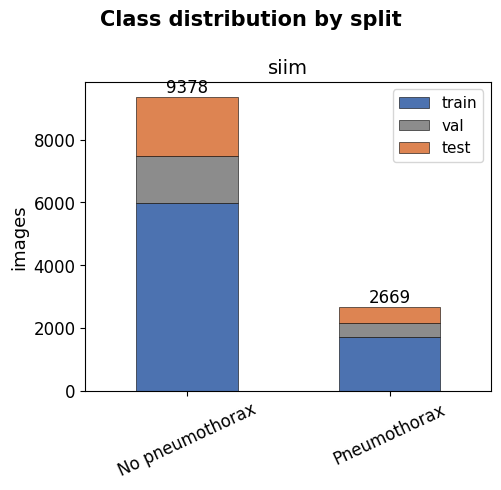

Domain           Class  train  val  test  total
  siim No pneumothorax   5989 1493  1896   9378
  siim    Pneumothorax   1720  435   514   2669


In [39]:
per_class = []
for name, D in DATA.items():
    m = D["manifest"]
    for k, c in enumerate(D["class_names"]):
        r = {"Domain": name, "Class": c, **{s: int(((m["label"] == k) & (m["split"] == s)).sum()) for s in ("train", "val", "test")}}
        r["total"] = r["train"] + r["val"] + r["test"]
        per_class.append(r)
per_class = pd.DataFrame(per_class)
per_class.to_csv(os.path.join(OUTPUT_DIR, "table1b_class_counts.csv"), index=False)

fig, axes = plt.subplots(1, len(DATA), figsize=(5.2 * len(DATA), 5), squeeze=False)
for ax, (name, D) in zip(axes[0], DATA.items()):
    sub = per_class[per_class["Domain"] == name].set_index("Class")[["train", "val", "test"]]
    sub.plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#8C8C8C", "#DD8452"], edgecolor="black", lw=0.4,
             legend=(ax is axes[0][0]))
    for i, tot in enumerate(sub.sum(axis=1)):
        ax.text(i, tot, str(int(tot)), ha="center", va="bottom", fontsize=12)
    ax.set_title(name); ax.set_xlabel(""); ax.set_ylabel("images"); ax.tick_params(axis="x", rotation=25)
plt.suptitle("Class distribution by split", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "fig1_class_distribution.png"), dpi=200); plt.show()
print(per_class.to_string(index=False))

---
# 3. Model

The same head for every backbone: global average pooling, batch norm, dropout and a dense layer that outputs **logits** (Grad-CAM needs the logits, not the softmax). The backbone table holds what changes between ResNet50 and DenseNet121: the preprocessing, the layer Grad-CAM reads from, a 14x14 layer for the resolution check, and where stage 2 starts unfreezing.

In [40]:
BACKBONES = {
    "resnet50": dict(build=tf.keras.applications.ResNet50,
                     preprocess=tf.keras.applications.resnet50.preprocess_input,      # RGB 0-255 -> BGR minus mean
                     cam_layer="conv5_block3_out", conv4_layer="conv4_block6_out",
                     stage_start={"conv5": "conv5_block1_1_conv", "conv4": "conv4_block1_1_conv"}),
    "densenet121": dict(build=tf.keras.applications.DenseNet121,
                        preprocess=tf.keras.applications.densenet.preprocess_input,  # 0-255 -> torch-style scaling
                        cam_layer="relu", conv4_layer="conv4_block24_concat",
                        stage_start={"conv5": "conv5_block1_0_bn", "conv4": "conv4_block1_0_bn"}),
}
BB = BACKBONES[CFG["backbone"]]
LAYERS = {"conv5": BB["cam_layer"], "conv4": BB["conv4_layer"]}       # 7x7 and 14x14 maps at 224 px
HEAD_LAYERS = ("gap", "head_bn", "head_dropout", "logits", "probs")

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr, **CFG["adam"]),
                  loss=tf.keras.losses.CategoricalCrossentropy(),
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

def build_model(num_classes):
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_0_255")
    x = BB["preprocess"](inputs)
    wfile = WEIGHT_FILES.get(CFG["backbone"])
    if wfile and os.path.exists(wfile):
        backbone = BB["build"](include_top=False, weights=None, input_tensor=x)
        backbone.load_weights(wfile)
    else:
        backbone = BB["build"](include_top=False, weights="imagenet", input_tensor=x)
    for layer in backbone.layers:
        layer.trainable = False
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = tf.keras.layers.BatchNormalization(name="head_bn")(x)
    x = tf.keras.layers.Dropout(CFG["dropout"], name="head_dropout")(x)
    logits = tf.keras.layers.Dense(num_classes, dtype="float32", name="logits")(x)
    probs = tf.keras.layers.Activation("softmax", dtype="float32", name="probs")(logits)
    model = tf.keras.Model(inputs, probs, name=f"{CFG['backbone']}_{num_classes}cls")
    compile_model(model, CFG["lr_stage1"])
    return model

def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def enable_finetuning(model):
    """Stage 2: unfreeze the chosen stage(s) by layer name, BN stays frozen. My first version unfroze
    nothing here without noticing, hence the assert."""
    before = count_trainable(model)
    names = [l.name for l in model.layers]
    start = names.index(BB["stage_start"][CFG["finetune_stage"]])
    for i, layer in enumerate(model.layers):
        if layer.name in HEAD_LAYERS:
            layer.trainable = True
        elif i >= start:
            layer.trainable = CFG["finetune_batchnorm"] or not isinstance(layer, tf.keras.layers.BatchNormalization)
        else:
            layer.trainable = False
    compile_model(model, CFG["lr_stage2"])
    after = count_trainable(model)
    assert after > before, "stage 2 did not unfreeze anything"
    print(f"  stage 2: trainable parameters {before:,} -> {after:,}")
    return before, after

print(f"model code ready ({CFG['backbone']}, Grad-CAM layer {LAYERS['conv5']}, 14x14 layer {LAYERS['conv4']})")

model code ready (resnet50, Grad-CAM layer conv5_block3_out, 14x14 layer conv4_block6_out)


A quick check I keep from the debugging of version 1: how much do backbone features vary between images when the input is 0-255 (correct) versus 0-1 (the old bug)? It only runs in `v2_main`.

In [41]:
if PROFILE == "v2_main":
    for name, D in DATA.items():
        paths = np.random.default_rng(0).permutation(D["manifest"].loc[D["manifest"]["split"] == "train", "path"].values)[:32]
        model = build_model(2)
        fe = tf.keras.Model(model.input, model.get_layer("gap").output)
        imgs = np.stack([read_image_rgb(p) for p in paths])
        spread = lambda f: float(np.mean(np.std(f, axis=0)) / (np.mean(np.abs(f)) + 1e-8))
        print(f"{name:15s} feature spread  0-255: {spread(fe.predict(imgs, verbose=0)):.3f}   "
              f"0-1: {spread(fe.predict(imgs / 255.0, verbose=0)):.3f}")
        del model, fe; tf.keras.backend.clear_session()
else:
    print("input-scaling check only runs in v2_main")

input-scaling check only runs in v2_main


### Training

Two stages: the head alone, then the head plus the chosen backbone stage. The checkpoint with the lowest validation loss over both stages is the one used for everything afterwards. `train_info.json` is written last, so its presence means a run finished.

In [42]:
def domain_dir(domain, seed, run_name=None):
    d = os.path.join(PROJECT_DIR, "outputs", run_name or RUN_NAME, domain, f"seed_{seed}")
    os.makedirs(d, exist_ok=True)
    return d

def plot_training_curves(log, n1, domain, d):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key in zip(axes, ("accuracy", "loss")):
        ax.plot(log["epoch"] + 1, log[key], label="train")
        ax.plot(log["epoch"] + 1, log["val_" + key], "--", label="val")
        ax.axvline(n1 + 0.5, color="k", ls=":", lw=1, label="stage 1 -> 2")
        ax.set_title(f"{domain} {key}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.savefig(os.path.join(d, "training_curves.png"), dpi=150); plt.close()

def train_domain(D, seed):
    domain, man, K = D["name"], D["manifest"], len(D["class_names"])
    d = domain_dir(domain, seed)
    tf.keras.backend.clear_session(); set_seed(seed)
    tr, va = man[man["split"] == "train"], man[man["split"] == "val"]
    train_ds = make_dataset(tr["path"], tr["label"], K, training=True, seed=seed, augmenter=build_augmenter(seed))
    val_ds = make_dataset(va["path"], va["label"], K)
    class_weight = None
    if CFG["use_class_weights"]:
        w = compute_class_weight("balanced", classes=np.arange(K), y=tr["label"].values)
        class_weight = {int(k): float(v) for k, v in enumerate(w)}
    print(f"\n--- training {domain}, seed {seed}: {len(tr)} train / {len(va)} val, class weights {class_weight}")

    model = build_model(K)
    best_path, log_path = os.path.join(d, "best.weights.h5"), os.path.join(d, "training_log.csv")
    if os.path.exists(log_path):
        os.remove(log_path)
    ckpt = tf.keras.callbacks.ModelCheckpoint(best_path, monitor=CFG["checkpoint_monitor"], mode="min",
                                              save_best_only=True, save_weights_only=True)
    logger = tf.keras.callbacks.CSVLogger(log_path, append=True)
    callbacks = lambda: [ckpt, logger,
                         tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["early_stop_patience"],
                                                          restore_best_weights=True, verbose=1),
                         tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=CFG["lr_plateau_factor"],
                                                              patience=CFG["lr_plateau_patience"], min_lr=CFG["min_lr"])]
    p1 = count_trainable(model)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=CFG["epochs_stage1"], callbacks=callbacks(),
                   class_weight=class_weight, verbose=2)
    n1 = len(h1.epoch)
    _, p2 = enable_finetuning(model)
    h2 = model.fit(train_ds, validation_data=val_ds, initial_epoch=n1, epochs=n1 + CFG["epochs_stage2"],
                   callbacks=callbacks(), class_weight=class_weight, verbose=2)
    model.load_weights(best_path)
    log = pd.read_csv(log_path)
    best = log.loc[log[CFG["checkpoint_monitor"]].idxmin()]
    info = dict(domain=domain, seed=seed, profile=PROFILE, backbone=CFG["backbone"], n_train=len(tr), n_val=len(va),
                class_weight=class_weight, stage1_epochs_run=n1, stage2_epochs_run=len(h2.epoch),
                trainable_params_stage1=p1, trainable_params_stage2=p2, selected_epoch=int(best["epoch"]) + 1,
                selected_in_stage=1 if int(best["epoch"]) < n1 else 2,
                selected_val_loss=float(best["val_loss"]), selected_val_acc=float(best["val_accuracy"]))
    save_json(info, os.path.join(d, "train_info.json"))
    plot_training_curves(log, n1, domain, d)
    print(f"  kept epoch {info['selected_epoch']} (stage {info['selected_in_stage']}), val loss {info['selected_val_loss']:.4f}")
    return model, info

def load_trained_model(D, seed, run_name=None):
    model = build_model(len(D["class_names"]))
    model.load_weights(os.path.join(domain_dir(D["name"], seed, run_name), "best.weights.h5"))
    return model

print("training functions ready")

training functions ready


---
# 4. Evaluation and attribution maps

In [43]:
def predict_manifest(model, df, K):
    return model.predict(make_dataset(df["path"], df["label"], K), verbose=0)

def auc_fn(y, p):
    if p.shape[1] == 2:
        return roc_auc_score(y, p[:, 1])
    return roc_auc_score(y, p, multi_class="ovr", average="macro", labels=list(range(p.shape[1])))

def stratified_bootstrap_ci(fn, y, p, B, seed=0):
    rng = np.random.default_rng(seed)
    by_class = [np.where(y == k)[0] for k in np.unique(y)]
    vals = []
    for _ in range(B):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in by_class])
        try:
            vals.append(fn(y[idx], p[idx]))
        except ValueError:
            pass
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

def expected_calibration_error(y, p, n_bins=15):
    conf, pred = p.max(1), p.argmax(1)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(ece)

def classification_metrics(y, p, class_names):
    y, p = np.asarray(y, int), np.asarray(p, float)
    K = len(class_names); pred = p.argmax(1)
    cm = confusion_matrix(y, pred, labels=list(range(K)))
    rep = classification_report(y, pred, labels=list(range(K)), target_names=class_names, output_dict=True, zero_division=0)
    B = CFG["n_bootstrap_cls"]
    bacc = lambda a, b: balanced_accuracy_score(a, b.argmax(1))
    return dict(
        n_test=int(len(y)), class_counts=np.bincount(y, minlength=K).tolist(),
        majority_baseline_acc=float(np.bincount(y, minlength=K).max() / len(y)),   # plain accuracy of always guessing the biggest class
        chance_balanced_acc=1.0 / K,
        accuracy=float(accuracy_score(y, pred)),
        accuracy_ci=stratified_bootstrap_ci(lambda a, b: accuracy_score(a, b.argmax(1)), y, p, B),
        balanced_accuracy=float(bacc(y, p)), balanced_accuracy_ci=stratified_bootstrap_ci(bacc, y, p, B),
        macro_f1=float(f1_score(y, pred, average="macro", zero_division=0)),
        cohen_kappa=float(cohen_kappa_score(y, pred)),
        auc=float(auc_fn(y, p)), auc_ci=stratified_bootstrap_ci(auc_fn, y, p, B),
        per_class={c: dict(precision=rep[c]["precision"], recall=rep[c]["recall"], f1=rep[c]["f1-score"],
                           support=int(rep[c]["support"])) for c in class_names},
        confusion_matrix=cm.tolist(),
        confusion_matrix_row_pct=(cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100).round(1).tolist(),
        ece=expected_calibration_error(y, p))

def evaluate_domain(model, D, seed):
    d = domain_dir(D["name"], seed)
    te = D["manifest"][D["manifest"]["split"] == "test"].reset_index(drop=True)
    p = predict_manifest(model, te, len(D["class_names"]))
    pred_df = pd.DataFrame({"path": te["path"], "image_id": te["image_id"], "group": te["group"].astype(str),
                            "label": te["label"], "pred": p.argmax(1), "gt_type": te["gt_type"]})
    for k, c in enumerate(D["class_names"]):
        pred_df[f"prob_{c}"] = p[:, k]
    pred_df["correct"] = (pred_df["pred"] == pred_df["label"]).astype(int)
    pred_df.to_csv(os.path.join(d, "predictions_test.csv"), index=False)
    met = classification_metrics(te["label"].values, p, D["class_names"])
    save_json(met, os.path.join(d, "metrics.json"))
    print(f"  {D['name']}: balanced acc {met['balanced_accuracy']:.3f} (chance {met['chance_balanced_acc']:.2f}), "
          f"AUC {met['auc']:.3f}, accuracy {met['accuracy']:.3f} (majority class {met['majority_baseline_acc']:.3f})")
    return met

print("evaluation functions ready")

evaluation functions ready


### Grad-CAM with a fixed target

The target is the same for every image of a dataset, so correct and misclassified images explain the same output:
* binary tasks: the positive-class margin $z_{pos} - z_{neg}$;
* brain MRI (3 classes): the true-class logit $z_y$ (my pre-declared primary) and, new in v5, the true-class margin $z_y - \log\sum_{j \ne y} e^{z_j}$, so that brain is comparable with the binary tasks. A raw logit also contains evidence shared by all classes ("this is a brain").

The predicted-class targets are kept only to show how much the target choice matters.

**Why I also keep the absolute map.** Grad-CAM applies a ReLU and keeps only evidence *for* the target. A missed lesion has, almost by definition, little positive evidence, so its map can look noisy and spread out even if the network did look at the lesion. For the primary target I therefore also store the absolute map |S|, and how much positive and negative evidence the signed map contains, so the comparison can be repeated without the ReLU.

In [44]:
def centre_prior(size=None, sigma_frac=0.25):
    size = size or IMG_SIZE
    yy, xx = np.mgrid[0:size, 0:size]; c = (size - 1) / 2.0; s = sigma_frac * size   # scales with the input size
    g = np.exp(-((xx - c) ** 2 + (yy - c) ** 2) / (2 * s * s))
    return (g / g.max()).astype(np.float32)
CENTRE_PRIOR = centre_prior()

def make_cam_model(model, layer=None):
    return tf.keras.Model(model.input, [model.get_layer(layer or LAYERS["conv5"]).output, model.get_layer("logits").output])

def primary_target_name(D):
    return "fixed_positive_margin" if len(D["class_names"]) == 2 else "fixed_true_class"

def gradcam_all_targets(cam_model, img_0_255, D, true_label):
    """Grad-CAM for every target from one forward pass.
    Returns {map name: (map, all_zero)}, the logits, and the evidence summary of the primary target."""
    x = tf.convert_to_tensor(img_0_255[None], tf.float32)
    K = len(D["class_names"])
    with tf.GradientTape(persistent=True) as tape:
        conv, logits = cam_model(x, training=False)
        z = logits[0]
        pred = tf.argmax(z)
        targets = {}
        if K == 2:
            pos = D["positive_class"]
            targets["fixed_positive_margin"] = z[pos] - z[1 - pos]
        else:
            y = int(true_label)
            targets["fixed_true_class"] = z[y]
            targets["fixed_true_margin"] = z[y] - tf.reduce_logsumexp(z - 1e9 * tf.one_hot(y, K))
        targets["predicted_logit"] = tf.gather(z, pred)
        targets["predicted_prob_legacy"] = tf.gather(tf.nn.softmax(logits)[0], pred)
    A = conv[0].numpy().astype(np.float32)
    prim = primary_target_name(D)
    maps, evidence = {}, {}
    for name, score in targets.items():
        g = tape.gradient(score, conv)
        signed = A @ tf.reduce_mean(g, axis=(1, 2))[0].numpy()      # sum_k alpha_k A^k, before the ReLU
        versions = {name: np.maximum(signed, 0.0)}
        if name == prim:
            versions[name + "_abs"] = np.abs(signed)
            evidence = dict(pos_mass=float(np.maximum(signed, 0).sum()), neg_mass=float(np.maximum(-signed, 0).sum()),
                            max_abs=float(np.abs(signed).max()))
        for vname, cam in versions.items():
            peak = float(cam.max()); zero = peak <= 1e-12
            cam = cam / peak if not zero else cam
            maps[vname] = (cv2.resize(cam.astype(np.float32), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR), zero)
    del tape
    return maps, z.numpy(), evidence

def localisation_metrics(cam, gt, taus):
    gt = np.asarray(gt).astype(bool); res = {}
    for tau in taus:
        a = cam >= tau
        union = np.logical_or(a, gt).sum()
        res[f"iou@{tau}"] = float(np.logical_and(a, gt).sum() / union) if union > 0 else np.nan
    total = float(cam.sum())
    res["energy_in_gt"] = float(cam[gt].sum() / total) if total > 0 else np.nan      # empty maps -> NaN, counted separately
    if cam.max() > 0:
        r, c = np.unravel_index(int(np.argmax(cam)), cam.shape); res["pointing_hit"] = float(gt[r, c])
    else:
        res["pointing_hit"] = np.nan
    res["gt_area_frac"] = float(gt.mean())            # what a uniform map would score
    b = max(1, int(round(0.10 * cam.shape[0])))
    border = np.zeros_like(gt); border[:b, :] = border[-b:, :] = border[:, :b] = border[:, -b:] = True
    border &= ~gt
    res["energy_border"] = float(cam[border].sum() / total) if total > 0 else np.nan
    res["border_area_frac"] = float(border.mean())
    return res

print("Grad-CAM functions ready; targets for this profile:",
      sorted({primary_target_name(D) for D in DATA.values()}))

Grad-CAM functions ready; targets for this profile: ['fixed_positive_margin']


In [45]:
def run_localisation(model, D, seed):
    """Grad-CAM metrics for every test image with ground truth (all targets + the centre prior)."""
    d = domain_dir(D["name"], seed)
    man = D["manifest"]
    test = man[(man["split"] == "test") & (man["gt_type"] != "none")]
    if len(test) == 0:
        return None
    preds = pd.read_csv(os.path.join(d, "predictions_test.csv")).set_index("path")
    cam_model = make_cam_model(model)
    rows, mismatch = [], 0
    for i, (_, r) in enumerate(test.iterrows()):
        gt = load_gt_mask(r)
        maps, logits, evidence = gradcam_all_targets(cam_model, read_image_rgb(r["path"]), D, r["label"])
        pred = int(preds.loc[r["path"], "pred"])
        mismatch += int(int(np.argmax(logits)) != pred)
        base = dict(path=r["path"], group=str(r["group"]), label=int(r["label"]), pred=pred,
                    correct=int(pred == int(r["label"])), **evidence)
        if len(D["class_names"]) == 2:
            base["logit_margin_pos"] = float(logits[D["positive_class"]] - logits[1 - D["positive_class"]])
        for tname, (cam, zero) in maps.items():
            rows.append({**base, "target": tname, "cam_all_zero": zero, **localisation_metrics(cam, gt, CFG["cam_thresholds"])})
        rows.append({**base, "target": "centre_prior_baseline", "cam_all_zero": False,
                     **localisation_metrics(CENTRE_PRIOR, gt, CFG["cam_thresholds"])})
        if i % 200 == 0:
            print(f"    Grad-CAM {i}/{len(test)}")
    loc = pd.DataFrame(rows)
    loc.to_csv(os.path.join(d, "localisation_per_sample.csv"), index=False)
    # mismatch = argmax at Grad-CAM time differs from the saved prediction (only near-ties, should be ~0)
    print(f"  {D['name']}: {len(test)} images with ground truth, {mismatch} near-tie mismatches")
    return loc

print("localisation runner ready")

localisation runner ready


---
# 5. Statistics used per run

Per seed I compare misclassified (M) with correctly classified (C) images *of the same true class*: bootstrap intervals for means and medians, Mann-Whitney, a permutation test and Cliff's delta. Holm's correction is applied across the seven metrics of the primary family. These per-seed numbers treat images as independent; the pooled analysis later resamples patients.

In [46]:
def cliffs_delta(a, b):
    """P(a > b) - P(a < b), via the Mann-Whitney U statistic."""
    u = sps.mannwhitneyu(a, b, alternative="two-sided").statistic
    return float(2.0 * u / (len(a) * len(b)) - 1.0)

def cliffs_label(d):        # Romano et al. (2006)
    a = abs(d)
    return "negligible" if a < 0.147 else "small" if a < 0.33 else "medium" if a < 0.474 else "large"

def boot_stat(a, fn, B, rng):
    return fn(a[rng.integers(0, len(a), (B, len(a)))], axis=1)

def perm_test_mean(a, b, B, rng):
    pooled = np.concatenate([a, b]); na = len(a); obs = a.mean() - b.mean()
    diffs = np.empty(B)
    for s in range(0, B, 1000):
        n = min(1000, B - s)
        perm = rng.permuted(np.tile(pooled, (n, 1)), axis=1)
        diffs[s:s + n] = perm[:, :na].mean(1) - perm[:, na:].mean(1)
    return float((np.sum(np.abs(diffs) >= abs(obs)) + 1) / (B + 1))

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def compare_groups(M, C, seed=0):
    M, C = np.asarray(M, float), np.asarray(C, float)
    out = dict(n_C=len(C), n_M=len(M))
    if len(M) < 3 or len(C) < 3:
        out["note"] = "fewer than 3 images in a group - not tested"
        return out
    rng = np.random.default_rng(seed); B = CFG["n_bootstrap"]
    for lab, arr in (("C", C), ("M", M)):
        out[f"mean_{lab}"] = float(arr.mean())
        out[f"mean_{lab}_ci"] = np.percentile(boot_stat(arr, np.mean, B, rng), [2.5, 97.5]).tolist()
        out[f"median_{lab}"] = float(np.median(arr))
        out[f"median_{lab}_ci"] = np.percentile(boot_stat(arr, np.median, B, rng), [2.5, 97.5]).tolist()
    dm = boot_stat(M, np.mean, B, rng) - boot_stat(C, np.mean, B, rng)
    out["delta_mean"], out["delta_mean_ci"] = float(M.mean() - C.mean()), np.percentile(dm, [2.5, 97.5]).tolist()
    out["delta_median"] = float(np.median(M) - np.median(C))
    if np.unique(np.concatenate([M, C])).size > 1:
        out["mwu_p"] = float(sps.mannwhitneyu(M, C, alternative="two-sided").pvalue)
        out["cliffs_delta_M_vs_C"] = cliffs_delta(M, C)
        out["cliffs_magnitude"] = cliffs_label(out["cliffs_delta_M_vs_C"])
    out["perm_p_delta_mean"] = perm_test_mean(M, C, CFG["n_permutations"], rng)
    return out

def primary_subset_name(D):
    pos = D.get("positive_class")
    return f"true={D['class_names'][pos]}" if pos is not None else "all_classes"

def run_statistics(loc, D, seed):
    d = domain_dir(D["name"], seed)
    metrics = [f"iou@{t}" for t in CFG["cam_thresholds"]] + ["energy_in_gt", "pointing_hit"]
    subsets = [("all_classes", loc)] + [(f"true={c}", loc[loc["label"] == k])
                                        for k, c in enumerate(D["class_names"]) if (loc["label"] == k).any()]
    rows = []
    for target in loc["target"].unique():
        for sname, sub in subsets:
            st = sub[sub["target"] == target]
            for metric in metrics:
                x = st[[metric, "correct"]].dropna()
                res = compare_groups(x.loc[x["correct"] == 0, metric].values, x.loc[x["correct"] == 1, metric].values, seed=seed)
                rows.append(dict(domain=D["name"], seed=seed, target=target, subset=sname, metric=metric,
                                 n_zero_maps=int(st["cam_all_zero"].sum()), **res))
    stats_df = pd.DataFrame(rows)
    if "mwu_p" not in stats_df:
        stats_df["mwu_p"] = np.nan
    fam = (stats_df["target"] == primary_target_name(D)) & (stats_df["subset"] == primary_subset_name(D)) & stats_df["mwu_p"].notna()
    stats_df["holm_p_primary_family"] = np.nan
    if fam.any():
        stats_df.loc[fam, "holm_p_primary_family"] = holm(stats_df.loc[fam, "mwu_p"].values)
    stats_df["is_primary_endpoint"] = fam & (stats_df["metric"] == CFG["primary_metric"])
    stats_df.to_csv(os.path.join(d, "localisation_stats.csv"), index=False)
    prim = stats_df[stats_df["is_primary_endpoint"]]
    if len(prim):
        r = prim.iloc[0]
        print(f"  primary ({primary_subset_name(D)}): energy C {r['mean_C']:.3f} (n={r['n_C']}) vs M {r['mean_M']:.3f} "
              f"(n={r['n_M']}), delta {r['delta_mean']:+.3f}, p={r['mwu_p']:.4f}, Cliff {r['cliffs_delta_M_vs_C']:+.2f}")
    return stats_df

print("per-run statistics ready")

per-run statistics ready


---
# 6. Running the experiments

### Frozen analysis plan for SIIM-ACR

Several reviewers noted that most of my analyses were added after I had seen results. For the SIIM-ACR replication I therefore write the plan down **before** training. The cell saves it with a hash and a time stamp; I commit this file to GitHub before the first training run, so the commit date shows that the plan came first. If the plan text is changed later, the cell warns.

In [47]:
SIIM_PLAN = """
Confirmatory analysis plan - SIIM-ACR pneumothorax replication (written before training).
Model: ImageNet ResNet50, same head and training protocol as the v3 chest model (conv4+conv5 fine-tuned),
224 px, seeds 42/43/44, image-level split 64/16/20 (this copy has no patient IDs), checkpoint = lowest validation loss.
Images analysed: test images with pneumothorax (pixel mask); correct = true positive, misclassified = false negative.
Primary target: positive-class logit margin. Primary endpoint: share of Grad-CAM energy inside the mask.
Inference: pooled over seeds, bootstrap over images (2000), 95% CI.
H1 (RQ1): Grad-CAM energy of correct predictions minus the centre prior (sigma 0.25) and minus the
    training-mask location prior, paired per image; reported with CI, no direction assumed.
H2 (RQ2, raw): misclassified minus correct difference in energy.
H3 (RQ2, adjusted): misclassification coefficient in a linear model energy ~ misclassified + log(lesion area) + seed,
    standard errors clustered by patient.
H4 (equivalence): Cliff's delta, 90% CI within +/-0.147 = equivalent; 95% CI excluding 0 = different; else inconclusive.
H5 (target): the difference in H2 recomputed with the predicted-class logit and softmax targets.
H6 (method): H2 and the enrichment difference recomputed with Integrated Gradients and occlusion.
H7 (ReLU): H2 recomputed with the absolute Grad-CAM map; positive/negative evidence mass compared between groups.
Decision rule for any correct-vs-misclassified effect: same sign in all three seeds and pooled 95% CI excluding 0.
Everything else is exploratory and will be labelled as such.
""".strip()

if "siim" in P["domains"]:
    plan_file = os.path.join(OUTPUT_DIR, "protocol_frozen.json")
    digest = hashlib.sha256(SIIM_PLAN.encode()).hexdigest()
    if not os.path.exists(plan_file):
        save_json(dict(plan=SIIM_PLAN, sha256=digest, frozen_at=time.strftime("%Y-%m-%d %H:%M:%S %Z"), cfg=CFG),
                  plan_file)
        print("plan frozen ->", plan_file, "\nCommit and push this file to GitHub BEFORE running the training cell.")
    else:
        saved = json.load(open(plan_file))
        print("plan frozen at", saved["frozen_at"], "| unchanged" if saved["sha256"] == digest
              else "| WARNING: the plan text differs from the frozen version")
else:
    print("not the SIIM profile - nothing to freeze")

plan frozen -> D:\01 Research work\Papar\0 Project\1 Cross-Domain Explanation Degradation Study\Source code\outputs\v5_siim\protocol_frozen.json 
Commit and push this file to GitHub BEFORE running the training cell.


### Training / evaluation driver

This is the only cell that trains. For each dataset and seed it trains (or reloads the finished checkpoint), evaluates on the test set, computes the attribution maps and the per-seed statistics. Grad-CAM files from before v5 lack the new columns, so they are recomputed once; after that they are reused.

In [ ]:
FORCE_RETRAIN = False
RUN_DOMAINS   = list(DATA)          # e.g. ["siim"] to work on one dataset
RUN_SEEDS     = SEEDS               # e.g. [42] to split a long training over several days

t_all = time.time()
for domain in RUN_DOMAINS:
    D = DATA[domain]
    for seed in RUN_SEEDS:
        t0 = time.time()
        d = domain_dir(domain, seed)
        finished = os.path.exists(os.path.join(d, "best.weights.h5")) and os.path.exists(os.path.join(d, "train_info.json"))
        if FORCE_RETRAIN or not finished:
            model, _ = train_domain(D, seed)
        else:
            tf.keras.backend.clear_session()
            model = load_trained_model(D, seed)
            print(f"\n--- {domain}, seed {seed}: using the saved checkpoint")
        evaluate_domain(model, D, seed)
        loc_file = os.path.join(d, "localisation_per_sample.csv")
        up_to_date = os.path.exists(loc_file) and "pos_mass" in pd.read_csv(loc_file, nrows=1).columns
        loc = pd.read_csv(loc_file) if up_to_date else run_localisation(model, D, seed)
        if loc is not None:
            run_statistics(loc, D, seed)
        del model; tf.keras.backend.clear_session()
        print(f"  ({(time.time() - t0) / 60:.1f} min)")
print(f"\nall runs done in {(time.time() - t_all) / 60:.1f} min")

---
# 7. Main results

### Helpers for pooling over seeds

Every analysis below pools the three seeds. The same image appears once per seed, and in brain MRI and chest radiographs one patient contributes several images, so the bootstrap resamples **patients** (`group`) and keeps all their images and seeds together. For skin and BACH there are no patient IDs, so the group is the image.

In [ ]:
N_BOOT = 2000          # patient-level resamples; 2000 keeps the run time reasonable

def load_loc(dname, seed, run_name=None):
    f = os.path.join(domain_dir(dname, seed, run_name), "localisation_per_sample.csv")
    if not os.path.exists(f):
        return None
    L = pd.read_csv(f)
    if "group" not in L:
        L["group"] = L["path"].map(GROUP_OF)
    L["group"] = L["group"].astype(str)
    L["seed"] = seed
    return L

def primary_rows(dname, target=None, keep_empty=False, run_name=None):
    """One row per image and seed for the primary comparison set (positive class, or all brain classes)."""
    D = DATA[dname]; target = target or primary_target_name(D)
    parts = [L for L in (load_loc(dname, s, run_name) for s in SEEDS) if L is not None]
    if not parts:
        return None
    L = pd.concat(parts, ignore_index=True)
    prior = L[L["target"] == "centre_prior_baseline"][["path", "seed", "energy_in_gt"]].rename(columns={"energy_in_gt": "centre_energy"})
    L = L[L["target"] == target].merge(prior, on=["path", "seed"], how="left")
    if D.get("positive_class") is not None:
        L = L[L["label"] == D["positive_class"]]
    if not keep_empty:
        L = L.dropna(subset=["energy_in_gt"])
    L["enrichment"] = L["energy_in_gt"] / L["gt_area_frac"].clip(lower=1e-6)
    L["energy_minus_centre"] = L["energy_in_gt"] - L["centre_energy"]          # prior-referenced energy
    return L.reset_index(drop=True)

def group_bootstrap(G, stat, B=N_BOOT, seed=0):
    """Resample patients: all images and seeds of a patient move together."""
    G = G.reset_index(drop=True)
    if len(G) == 0:
        return np.nan, np.full(B, np.nan)
    rng = np.random.default_rng(seed)
    idx_by = {g: np.asarray(ix) for g, ix in G.groupby("group").indices.items()}
    keys = np.array(list(idx_by))
    vals = []
    for b in range(B):
        pick = keys[rng.integers(0, len(keys), len(keys))]
        vals.append(stat(G.iloc[np.concatenate([idx_by[k] for k in pick])]))
    return stat(G), np.asarray(vals, float)      # stat may return one number or a tuple

def ci(vals, level=95):
    lo = (100 - level) / 2
    return np.round(np.nanpercentile(vals, [lo, 100 - lo]), 3).tolist()

def cliffs_or_nan(m, c):
    m, c = np.asarray(m, float), np.asarray(c, float)
    m, c = m[~np.isnan(m)], c[~np.isnan(c)]
    return cliffs_delta(m, c) if len(m) and len(c) else np.nan

mc_delta  = lambda col: (lambda X: X.loc[X["correct"] == 0, col].mean() - X.loc[X["correct"] == 1, col].mean())
mc_cliffs = lambda col: (lambda X: cliffs_or_nan(X.loc[X["correct"] == 0, col], X.loc[X["correct"] == 1, col]))

def testable(X, k=3):
    return (X["correct"] == 0).sum() >= k and (X["correct"] == 1).sum() >= k

def seed_signs(G, col):
    """Sign of mean(M) - mean(C) in each seed, e.g. '- - +'; n = fewer than 3 images in a group."""
    return " ".join("n" if not testable(G[G["seed"] == s]) else ("+" if mc_delta(col)(G[G["seed"] == s]) > 0 else "-")
                    for s in SEEDS)

def decision_rule(signs, ci95):
    same = "n" not in signs and len(set(signs.split())) == 1
    return "supported" if same and (ci95[0] > 0 or ci95[1] < 0) else "not supported"

LOC_DOMAINS = [d for d in ["skin", "chest_xray", "brain_figshare", "siim"] if d in DATA]
# Analyses that need the model again (sanity check, Grad-CAM++, deletion, IG, occlusion) are slow. In v2_main
# skin and chest are only the sensitivity analysis (their main models are v3), so there I run them for brain only.
GPU_DOMAINS = ["brain_figshare"] if PROFILE == "v2_main" else list(LOC_DOMAINS)
GPU_DOMAINS = [d for d in GPU_DOMAINS if d in DATA]
print("pooling helpers ready | ground truth:", LOC_DOMAINS, "| model-based analyses:", GPU_DOMAINS)

### Classification performance (Table 4 in the paper)

Mean and SD over the three seeds. The "majority" column is the plain accuracy of always predicting the biggest class; balanced accuracy is compared with chance (1 / number of classes), not with that column.

In [ ]:
def seed_dirs(domain, run_name=None):
    return sorted(glob.glob(os.path.join(PROJECT_DIR, "outputs", run_name or RUN_NAME, domain, "seed_*")))

def mean_sd(vals):
    vals = [v for v in vals if v is not None]
    return f"{np.mean(vals):.3f} +/- {np.std(vals, ddof=1):.3f}" if len(vals) > 1 else f"{vals[0]:.3f}"

rows, captions = [], []
for domain, D in DATA.items():
    runs = [json.load(open(os.path.join(s, "metrics.json"))) for s in seed_dirs(domain) if os.path.exists(os.path.join(s, "metrics.json"))]
    if not runs:
        continue
    row = dict(Domain=domain, n_test=runs[0]["n_test"], seeds=len(runs), Majority_acc=round(runs[0]["majority_baseline_acc"], 3),
               Chance_bal_acc=round(runs[0]["chance_balanced_acc"], 3))
    for key in ("accuracy", "balanced_accuracy", "macro_f1", "cohen_kappa", "auc"):
        row[key] = mean_sd([r[key] for r in runs])
    for c in D["class_names"]:
        row[f"recall_{c}"] = mean_sd([r["per_class"][c]["recall"] for r in runs])
    rows.append(row)
    cm_pct = np.array(runs[0]["confusion_matrix_row_pct"])
    for i, ci_ in enumerate(D["class_names"]):
        worst = int(np.argmax(np.where(np.arange(len(D["class_names"])) == i, -1, cm_pct[i])))
        captions.append(f"{domain}: {cm_pct[i, i]:.1f}% of {ci_} correct; most common error {D['class_names'][worst]} ({cm_pct[i, worst]:.1f}%)")
cls_table = pd.DataFrame(rows)
cls_table.to_csv(os.path.join(OUTPUT_DIR, "table_classification.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "caption_facts.txt"), "w") as f:
    f.write("\n".join(captions))
display(cls_table)

### Primary endpoint: correct vs misclassified (Table 8)

Per seed: the image-level test from section 5 plus a patient-level bootstrap interval. Pooled: patient-level bootstrap over all seeds. The decision rule was fixed before I analysed seeds 43 and 44: same sign in all three seeds **and** a pooled interval that excludes zero.

In [ ]:
rows, pooled = [], {}
for dname in LOC_DOMAINS:
    D = DATA[dname]
    G = primary_rows(dname)
    if G is None:
        continue
    for s in SEEDS:
        fs = os.path.join(domain_dir(dname, s), "localisation_stats.csv")
        if not os.path.exists(fs):
            continue
        st = pd.read_csv(fs); r = st[st["is_primary_endpoint"] == True]
        X = G[G["seed"] == s]
        if not len(r) or not testable(X):
            rows.append(dict(domain=dname, seed=s, note="not testable")); continue
        r = r.iloc[0]
        _, bv = group_bootstrap(X, mc_delta("energy_in_gt"), B=2000, seed=s)
        rows.append(dict(domain=dname, seed=s, n_C=r["n_C"], n_M=r["n_M"], patients=X["group"].nunique(),
                         mean_C=r["mean_C"], mean_M=r["mean_M"], median_C=r["median_C"], median_M=r["median_M"],
                         delta=r["delta_mean"], delta_ci_patient=ci(bv), p=r["mwu_p"],
                         p_holm=r["holm_p_primary_family"], cliffs=r["cliffs_delta_M_vs_C"]))
    est, bv = group_bootstrap(G, mc_delta("energy_in_gt"))
    signs = seed_signs(G, "energy_in_gt")
    pooled[dname] = dict(delta=round(est, 3), ci=ci(bv), images=G["path"].nunique(), patients=G["group"].nunique(),
                         seed_signs=signs, rule=decision_rule(signs, ci(bv)),
                         empty_maps_C=int(primary_rows(dname, keep_empty=True).query("correct == 1")["energy_in_gt"].isna().sum()),
                         empty_maps_M=int(primary_rows(dname, keep_empty=True).query("correct == 0")["energy_in_gt"].isna().sum()))
seed_table = pd.DataFrame(rows)
seed_table.to_csv(os.path.join(OUTPUT_DIR, "table_primary_per_seed.csv"), index=False)
save_json(pooled, os.path.join(OUTPUT_DIR, "pooled_primary_endpoint.json"))
display(seed_table.round(3))
for d, v in pooled.items():
    print(f"{d:15s} pooled delta {v['delta']:+.3f} {v['ci']}  ({v['images']} images, {v['patients']} patients), "
          f"signs {v['seed_signs']} -> {v['rule']}; empty maps C/M {v['empty_maps_C']}/{v['empty_maps_M']}")

### Medians, pointing game and the model-free baselines

The pointing game now comes with a patient-level interval for correct predictions, as one reviewer asked.

In [ ]:
rows = []
for dname in LOC_DOMAINS:
    G = primary_rows(dname)
    if G is None:
        continue
    C, M = G[G["correct"] == 1], G[G["correct"] == 0]
    pt, pv = group_bootstrap(C, lambda X: X["pointing_hit"].mean(), B=2000)
    allp = pd.concat([L for L in (load_loc(dname, s) for s in SEEDS) if L is not None])
    cp = allp[(allp["target"] == "centre_prior_baseline") & allp["path"].isin(G["path"])].drop_duplicates("path")
    rows.append(dict(domain=dname, energy_C=C["energy_in_gt"].mean(), energy_M=M["energy_in_gt"].mean(),
                     median_C=C["energy_in_gt"].median(), median_M=M["energy_in_gt"].median(),
                     pointing_C=pt, pointing_C_ci=ci(pv), pointing_M=M["pointing_hit"].mean(),
                     centre_prior_energy=cp["energy_in_gt"].mean(), centre_prior_pointing=cp["pointing_hit"].mean(),
                     uniform_energy=G.drop_duplicates("path")["gt_area_frac"].mean()))
base_table = pd.DataFrame(rows)
base_table.to_csv(os.path.join(OUTPUT_DIR, "table_baselines_pointing.csv"), index=False)
display(base_table.round(3))

### Border attention by true class (exploratory)

Share of Grad-CAM energy in the outer 10% of the image, lesion pixels excluded. Section 9 tests with deletion whether the border actually changes predictions.

In [ ]:
rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    for s in SEEDS:
        L = load_loc(dname, s)
        if L is None:
            continue
        L = L[L["target"] == primary_target_name(D)].dropna(subset=["energy_border"])
        for k, c in enumerate(D["class_names"]):
            S = L[L["label"] == k]
            if not len(S):
                continue
            r = compare_groups(S.loc[S["correct"] == 0, "energy_border"].values, S.loc[S["correct"] == 1, "energy_border"].values, seed=s)
            rows.append(dict(domain=dname, seed=s, true_class=c, uniform=round(S["border_area_frac"].mean(), 3),
                             n_C=r["n_C"], n_M=r["n_M"], mean_C=r.get("mean_C"), mean_M=r.get("mean_M"),
                             delta=r.get("delta_mean"), delta_ci=r.get("delta_mean_ci"), p=r.get("mwu_p")))
border_table = pd.DataFrame(rows)
border_table.to_csv(os.path.join(OUTPUT_DIR, "table_border_by_class.csv"), index=False)
display(border_table.round(3) if len(border_table) else "no localisation data in this profile")

### Classification sensitivity checks (seed 42)

Kaggle brain without the test images that have a near-identical training image, and ChestX-ray14 with a patient-level bootstrap and without the patients I forced into the test set.

In [ ]:
def cluster_bootstrap_ci(fn, y, p, groups, B=2000, seed=0):
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    idx_by = {g: np.where(groups == g)[0] for g in ug}; vals = []
    for _ in range(B):
        idx = np.concatenate([idx_by[g] for g in rng.choice(ug, len(ug), replace=True)])
        try: vals.append(fn(y[idx], p[idx]))
        except ValueError: pass
    return np.percentile(vals, [2.5, 97.5]).round(3).tolist() if vals else None

bacc = lambda a, b: balanced_accuracy_score(a, b.argmax(1))
s0 = SEEDS[0]
if "brain" in DATA and os.path.exists(os.path.join(domain_dir("brain", s0), "predictions_test.csv")):
    man = DATA["brain"]["manifest"]; cn = DATA["brain"]["class_names"]
    pr = pd.read_csv(os.path.join(domain_dir("brain", s0), "predictions_test.csv")).merge(man[["path", "dhash"]], on="path")
    clean = pr[~pr["dhash"].isin(set(man.loc[man["split"] != "test", "dhash"]))]
    for name, sub in (("all", pr), ("without near-duplicates", clean)):
        y, p = sub["label"].values, sub[[f"prob_{c}" for c in cn]].values
        print(f"Kaggle brain {name}: n={len(sub)}, balanced acc {bacc(y, p):.3f} {stratified_bootstrap_ci(bacc, y, p, 2000)}")
if "chest_xray" in DATA and os.path.exists(os.path.join(domain_dir("chest_xray", s0), "predictions_test.csv")):
    man = DATA["chest_xray"]["manifest"]
    pr = pd.read_csv(os.path.join(domain_dir("chest_xray", s0), "predictions_test.csv"))
    forced = pr["group"].astype(str).isin(set(man.loc[man["gt_type"] == "bbox", "group"].astype(str)))
    for name, sub in (("all test", pr), ("without forced box patients", pr[~forced])):
        if sub["label"].nunique() < 2:
            continue
        y, p, g = sub["label"].values, sub[["prob_Normal", "prob_Disease"]].values, sub["group"].astype(str).values
        print(f"chest {name}: n={len(sub)}, patients={len(np.unique(g))}, balanced acc {bacc(y, p):.3f} "
              f"{cluster_bootstrap_ci(bacc, y, p, g)}, AUC {auc_fn(y, p):.3f} {cluster_bootstrap_ci(auc_fn, y, p, g)}")
print("sensitivity checks done (only for datasets in this profile)")

### Lesion size and class composition

Misclassified malignant skin lesions turned out to be smaller, and misclassified brain slices larger (because errors are mostly gliomas and meningiomas). Enrichment = energy / lesion area fraction (1 = a uniform map).

In [ ]:
rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    G = primary_rows(dname)
    if G is None:
        continue
    subsets = [(primary_subset_name(D), G)]
    if D.get("positive_class") is None:
        subsets += [(f"true={c}", G[G["label"] == k]) for k, c in enumerate(D["class_names"])]
    for sname, X in subsets:
        for s in SEEDS:
            Xs = X[X["seed"] == s]
            for metric in ("gt_area_frac", "energy_in_gt", "enrichment"):
                r = compare_groups(Xs.loc[Xs["correct"] == 0, metric].values, Xs.loc[Xs["correct"] == 1, metric].values, seed=s)
                rows.append(dict(domain=dname, subset=sname, seed=s, metric=metric, n_C=r["n_C"], n_M=r["n_M"],
                                 mean_C=r.get("mean_C"), mean_M=r.get("mean_M"), median_C=r.get("median_C"),
                                 median_M=r.get("median_M"), p=r.get("mwu_p")))
size_table = pd.DataFrame(rows)
size_table.to_csv(os.path.join(OUTPUT_DIR, "table_size_check.csv"), index=False)
display(size_table.round(3) if len(size_table) else "no localisation data in this profile")

---
# 8. Robustness of Grad-CAM itself

### Model-randomisation sanity check (Adebayo et al.)

Randomise the weights from the top down (output layer, then conv5, then conv4) and see whether the maps change. Up to 100 images per seed, now for all three seeds.

In [ ]:
def primary_score(logits, D, true_label):
    if len(D["class_names"]) == 2:
        pos = D["positive_class"]
        return logits[0, pos] - logits[0, 1 - pos]
    return logits[0, int(true_label)]

def cams_for_layer(cam_model, img, D, true_label):
    """Grad-CAM and Grad-CAM++ (closed form with an exponential score) from one backward pass."""
    x = tf.convert_to_tensor(img[None], tf.float32)
    with tf.GradientTape() as tape:
        conv, logits = cam_model(x, training=False)
        score = primary_score(logits, D, true_label)
    g = tape.gradient(score, conv)[0].numpy().astype(np.float64)
    A = conv[0].numpy().astype(np.float64)
    out = {"gradcam": np.maximum(A @ g.mean(axis=(0, 1)), 0)}
    g2, g3 = g ** 2, g ** 3
    denom = 2 * g2 + A.sum(axis=(0, 1)) * g3
    safe = np.abs(denom) > 1e-12
    alpha = np.where(safe, g2 / np.where(safe, denom, 1.0), 0.0)
    out["gradcampp"] = np.maximum(A @ (alpha * np.maximum(g, 0)).sum(axis=(0, 1)), 0)
    for k, m in out.items():
        m = m / m.max() if m.max() > 0 else m
        out[k] = cv2.resize(m.astype(np.float32), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    return out

def gt_test_rows(D, seed):
    """Test images with ground truth in the primary comparison set, with the saved prediction."""
    man = D["manifest"]
    te = man[(man["split"] == "test") & (man["gt_type"] != "none")]
    pr = pd.read_csv(os.path.join(domain_dir(D["name"], seed), "predictions_test.csv")).set_index("path")
    te = te.assign(pred=[int(pr.loc[p, "pred"]) for p in te["path"]])
    te["correct"] = (te["pred"] == te["label"]).astype(int)
    pos = D.get("positive_class")
    return te if pos is None else te[te["label"] == pos]

def randomise(model, upto):
    prefixes = {"logits": ("logits",), "conv5": ("logits", "conv5_"), "conv4": ("logits", "conv5_", "conv4_")}[upto]
    rng = np.random.default_rng(0)
    for layer in model.layers:
        if layer.name.startswith(prefixes) and isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.Dense)):
            for w in layer.weights:
                v = w.numpy(); sd = float(v.std()) or 0.01
                w.assign(rng.normal(0, sd, v.shape).astype(v.dtype))

N_SANITY = 100
rows = []
for dname in GPU_DOMAINS:
    D = DATA[dname]
    for seed in SEEDS:
        pool = gt_test_rows(D, seed)
        te = pool.sample(min(N_SANITY, len(pool)), random_state=0)
        tf.keras.backend.clear_session()
        cm_t = make_cam_model(load_trained_model(D, seed), LAYERS["conv5"])
        ref = {r["path"]: cams_for_layer(cm_t, read_image_rgb(r["path"]), D, r["label"])["gradcam"] for _, r in te.iterrows()}
        for level in ("logits", "conv5", "conv4"):
            m = load_trained_model(D, seed); randomise(m, level)
            cm_r = make_cam_model(m, LAYERS["conv5"])
            rhos, e_tr, e_rd, n_const = [], [], [], 0
            for _, r in te.iterrows():
                gt = load_gt_mask(r)
                cam_r = cams_for_layer(cm_r, read_image_rgb(r["path"]), D, r["label"])["gradcam"]
                n_const += int(cam_r.max() <= 0)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    rho = spearmanr(ref[r["path"]].ravel(), cam_r.ravel()).correlation
                rhos.append(0.0 if np.isnan(rho) else rho)
                e_tr.append(localisation_metrics(ref[r["path"]], gt, [0.5])["energy_in_gt"])
                e_rd.append(localisation_metrics(cam_r, gt, [0.5])["energy_in_gt"])
            rows.append(dict(domain=dname, seed=seed, randomised_up_to=level, n=len(te), constant_maps=n_const,
                             spearman_median=float(np.median(rhos)),
                             spearman_iqr=[round(float(np.percentile(rhos, 25)), 2), round(float(np.percentile(rhos, 75)), 2)],
                             energy_trained=float(np.nanmean(e_tr)), energy_randomised=float(np.nanmean(e_rd))))
            del m, cm_r
        print(f"  {dname} seed {seed} done")
sanity = pd.DataFrame(rows)
sanity.to_csv(os.path.join(OUTPUT_DIR, "table_sanity_check.csv"), index=False)
display(sanity.round(3) if len(sanity) else "no localisation data in this profile")

### Grad-CAM++ and 14x14 maps

The primary analysis repeated with a second CAM method and at the conv4 layer (four times more cells), pooled over seeds with the patient bootstrap, overall and per tumour type.

In [ ]:
per_image = []
for dname in GPU_DOMAINS:
    D = DATA[dname]
    for seed in SEEDS:
        te = gt_test_rows(D, seed)
        tf.keras.backend.clear_session()
        model = load_trained_model(D, seed)
        cms = {ln: make_cam_model(model, l) for ln, l in LAYERS.items()}
        for _, r in te.iterrows():
            gt, img = load_gt_mask(r), read_image_rgb(r["path"])
            for ln, cmod in cms.items():
                for meth, cam in cams_for_layer(cmod, img, D, r["label"]).items():
                    met = localisation_metrics(cam, gt, [0.5])
                    per_image.append(dict(domain=dname, seed=seed, layer=ln, method=meth, path=r["path"], group=str(r["group"]),
                                          label=int(r["label"]), correct=int(r["correct"]), gt_area_frac=met["gt_area_frac"],
                                          energy_in_gt=met["energy_in_gt"], pointing_hit=met["pointing_hit"]))
        del model, cms
        print(f"  {dname} seed {seed} done")
PI = pd.DataFrame(per_image)
PI.to_csv(os.path.join(OUTPUT_DIR, "methods_layers_per_image.csv"), index=False)

rows = []
for (dname, ln, meth), G in (PI.groupby(["domain", "layer", "method"]) if len(PI) else []):
    G = G.dropna(subset=["energy_in_gt"])
    subsets = [("primary", G)]
    if DATA[dname].get("positive_class") is None:
        subsets += [(f"true={c}", G[G["label"] == k]) for k, c in enumerate(DATA[dname]["class_names"])]
    for sname, X in subsets:
        if not testable(X):
            continue
        est, bv = group_bootstrap(X, mc_delta("energy_in_gt"), B=2000)
        rows.append(dict(domain=dname, subset=sname, layer=ln, method=meth, energy_C=X.loc[X["correct"] == 1, "energy_in_gt"].mean(),
                         energy_M=X.loc[X["correct"] == 0, "energy_in_gt"].mean(), delta=est, ci=ci(bv),
                         seed_signs=seed_signs(X, "energy_in_gt")))
robust_table = pd.DataFrame(rows)
robust_table.to_csv(os.path.join(OUTPUT_DIR, "table_methods_layers_pooled.csv"), index=False)
display(robust_table.round(3) if len(robust_table) else "no localisation data in this profile")

---
# 9. Is Grad-CAM better than a map that ignores the image? (RQ1)

A Gaussian in the image centre is the simplest "explanation" that knows nothing about the image. Lesions are not placed at random, though, so I also use a dataset-specific prior: the average lesion mask of the training images. ChestX-ray14 has no boxes in training, so its prior is the average of all *other* test boxes (leave-one-out); this one is built from test data and I label it that way.

Everything is paired: for each test image the Grad-CAM energy (correct predictions, all seeds) minus the prior's energy **on the same image**, with a patient-level bootstrap. The width of the centre prior (0.25 of the image) was my own choice, so 0.15 and 0.35 are shown as well.

In [ ]:
def accumulate_masks(rows):
    total, n = None, 0
    for _, r in rows.iterrows():
        m = load_gt_mask(r).astype(np.float32)
        total = m if total is None else total + m
        n += 1
    return total, n

def prior_energies(dname):
    """Energy inside each test lesion for the centre priors and the dataset prior (one row per image)."""
    D, man = DATA[dname], DATA[dname]["manifest"]
    te = gt_test_rows(D, SEEDS[0])
    train_gt = man[(man["split"] != "test") & (man["gt_type"] != "none")]
    if D.get("positive_class") is not None:
        train_gt = train_gt[train_gt["label"] == D["positive_class"]]
    loo = len(train_gt) == 0
    if loo:
        total, n = accumulate_masks(man[(man["split"] == "test") & (man["gt_type"] != "none")])
        source = f"{n} test masks, leave-one-out (test-derived)"
    else:
        total, n = accumulate_masks(train_gt)
        source = f"{n} training masks"
    centres = {s: centre_prior(sigma_frac=s) for s in (0.15, 0.25, 0.35)}
    rows = []
    for _, r in te.iterrows():
        gt = load_gt_mask(r)
        prior = total - gt if loo else total
        prior = prior / prior.max() if prior.max() > 0 else prior
        row = dict(path=r["path"], group=str(r["group"]), uniform=float(gt.mean()))
        row["dataset_prior"] = localisation_metrics(prior.astype(np.float32), gt, [0.5])["energy_in_gt"]
        row["dataset_prior_pointing"] = localisation_metrics(prior.astype(np.float32), gt, [0.5])["pointing_hit"]
        for s, cp in centres.items():
            row[f"centre_{s}"] = localisation_metrics(cp, gt, [0.5])["energy_in_gt"]
        rows.append(row)
    return pd.DataFrame(rows), source

rows, PRIORS = [], {}
for dname in LOC_DOMAINS:
    G = primary_rows(dname)
    if G is None:
        continue
    PR, source = prior_energies(dname)
    PRIORS[dname] = PR
    PR.to_csv(os.path.join(OUTPUT_DIR, f"priors_per_image_{dname}.csv"), index=False)
    C = G[G["correct"] == 1].merge(PR.drop(columns="group"), on="path")
    for prior in ("centre_0.15", "centre_0.25", "centre_0.35", "dataset_prior", "uniform"):
        est, bv = group_bootstrap(C, lambda X, p=prior: (X["energy_in_gt"] - X[p]).mean())
        rows.append(dict(domain=dname, prior=prior, prior_source=source if prior == "dataset_prior" else "",
                         n_images=C["path"].nunique(), patients=C["group"].nunique(),
                         gradcam_correct=C["energy_in_gt"].mean(), prior_energy=C[prior].mean(),
                         gradcam_minus_prior=est, ci95=ci(bv)))
    print(f"{dname}: dataset prior from {source}")
prior_table = pd.DataFrame(rows)
prior_table.to_csv(os.path.join(OUTPUT_DIR, "table_rq1_priors.csv"), index=False)
display(prior_table.round(3) if len(prior_table) else "no localisation data in this profile")

---
# 10. Is the difference built into Grad-CAM? (ReLU check)

Grad-CAM throws away negative evidence. If misclassified images have mostly negative evidence for the target, their maps become small and noisy by construction. Three checks:
1. how many maps are completely empty in each group;
2. the share of positive evidence, pos / (pos + neg), before the ReLU;
3. the correct-vs-misclassified comparison repeated for every target, including the absolute map |S| and (brain) the true-class margin.

Table 3 is also the data behind the target figure (Fig. G).

In [ ]:
rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    G = primary_rows(dname, keep_empty=True)
    if G is None:
        continue
    G["pos_share"] = G["pos_mass"] / (G["pos_mass"] + G["neg_mass"]).replace(0, np.nan)
    for flag, name in ((1, "correct"), (0, "misclassified")):
        X = G[G["correct"] == flag]
        rows.append(dict(domain=dname, group=name, n=len(X), empty_maps=int(X["energy_in_gt"].isna().sum()),
                         empty_pct=round(100 * X["energy_in_gt"].isna().mean(), 1),
                         pos_share_mean=X["pos_share"].mean(), pos_share_median=X["pos_share"].median()))
    if testable(G):
        est, bv = group_bootstrap(G, mc_delta("pos_share"))
        rows.append(dict(domain=dname, group="M - C", pos_share_mean=est, pos_share_ci95=ci(bv),
                         seed_signs=seed_signs(G, "pos_share")))
relu_table = pd.DataFrame(rows)
relu_table.to_csv(os.path.join(OUTPUT_DIR, "table_relu_evidence.csv"), index=False)
display(relu_table.round(3) if len(relu_table) else "no localisation data in this profile")

rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    L0 = load_loc(dname, SEEDS[0])
    if L0 is None:
        continue
    for target in [t for t in L0["target"].unique() if t != "centre_prior_baseline"]:
        G = primary_rows(dname, target=target)
        if not testable(G):
            continue
        for col in ("energy_in_gt", "enrichment"):
            est, bv = group_bootstrap(G, mc_delta(col), seed=1)
            signs = seed_signs(G, col)
            rows.append(dict(domain=dname, target=target, metric=col, primary=target == primary_target_name(D),
                             n_C=int((G["correct"] == 1).sum()), n_M=int((G["correct"] == 0).sum()),
                             mean_C=G.loc[G["correct"] == 1, col].mean(), mean_M=G.loc[G["correct"] == 0, col].mean(),
                             delta=est, ci95=ci(bv), seed_signs=signs, rule=decision_rule(signs, ci(bv))))
target_table = pd.DataFrame(rows)
target_table.to_csv(os.path.join(OUTPUT_DIR, "table_targets_pooled.csv"), index=False)
display(target_table.round(3) if len(target_table) else "no localisation data in this profile")

---
# 11. Equivalence: is "no difference" really no difference?

A non-significant test is not evidence of no effect. I use Cliff's delta (the effect size I declared before the v4 run): the 90% CI inside +/-0.147 ("negligible", Romano et al. 2006) = equivalent; the 95% CI excluding 0 = different; otherwise inconclusive. Because 0.147 is a convention and not a clinical threshold, I also show margins of 0.11 and 0.28, a margin of +/-0.05 on the mean energy scale, and the smallest difference the data could detect (80% power, two-sided 5%).

In [ ]:
MARGINS = (0.11, 0.147, 0.28)
MEAN_MARGIN = 0.05

def verdict(d_ci95, c_ci90, margin=0.147):
    different = d_ci95[0] > 0 or d_ci95[1] < 0
    equivalent = c_ci90[0] > -margin and c_ci90[1] < margin
    if different and equivalent: return "different, negligible size"
    if different:                return "different"
    if equivalent:               return "equivalent"
    return "inconclusive"

rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    for target in (primary_target_name(D), primary_target_name(D) + "_abs"):
        G = primary_rows(dname, target=target)
        if G is None or not len(G):
            continue
        subsets = [("primary", G)]
        if D.get("positive_class") is None:
            subsets += [(f"true={c}", G[G["label"] == k]) for k, c in enumerate(D["class_names"])]
        for sname, X in subsets:
            if not testable(X):
                rows.append(dict(domain=dname, target=target, subset=sname, verdict_0147="too few errors")); continue
            for col in ("energy_in_gt", "enrichment"):
                both = lambda Y, c=col: (mc_delta(c)(Y), mc_cliffs(c)(Y))
                (d, cd), bv = group_bootstrap(X, both, seed=2)
                dci, cci90 = ci(bv[:, 0]), ci(bv[:, 1], 90)
                row = dict(domain=dname, target=target, subset=sname, metric=col, images=X["path"].nunique(),
                           patients=X["group"].nunique(), delta=d, delta_ci95=dci, delta_ci90=ci(bv[:, 0], 90),
                           cliffs=cd, cliffs_ci90=cci90, cliffs_ci95=ci(bv[:, 1]),
                           mde_80=round(2.8 * float(np.nanstd(bv[:, 0])), 3))
                for m in MARGINS:
                    row[f"verdict_{str(m).replace('.', '')}"] = verdict(dci, cci90, m)
                if col == "energy_in_gt":
                    row["verdict_mean_005"] = verdict(dci, ci(bv[:, 0], 90), MEAN_MARGIN)
                rows.append(row)
eq_table = pd.DataFrame(rows)
eq_table.to_csv(os.path.join(OUTPUT_DIR, "table_equivalence.csv"), index=False)
show = [c for c in ("domain", "target", "subset", "metric", "delta", "delta_ci95", "cliffs", "cliffs_ci90",
                    "verdict_011", "verdict_0147", "verdict_028", "verdict_mean_005", "mde_80") if c in eq_table]
display(eq_table[show].round(3) if len(eq_table) else "no localisation data in this profile")

---
# 12. Lesion size and other image properties (regression)

Misclassified and correct images differ in lesion size, and size alone changes how much energy can fall inside a lesion. The **main model** adjusts for size only: energy ~ misclassified + log(lesion area) + seed (+ tumour type for brain). Standard errors are clustered by patient.

Prediction confidence is *not* in the main model: misclassification and low confidence are almost the same thing, so adjusting for confidence would remove part of the effect I want to measure. It appears only as a sensitivity model, together with lesion contrast, shape, position and image sharpness, a quadratic size term, and a fractional logit model (energy is a proportion between 0 and 1).

In [ ]:
def lesion_descriptors(row):
    """Lesion contrast against its surrounding ring, compactness, distance from the image centre, image sharpness."""
    img = read_image_rgb(row["path"])
    gray = cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)
    gt = load_gt_mask(row).astype(np.uint8)
    ring_px = max(3, IMG_SIZE // 20)
    ring = (cv2.dilate(gt, np.ones((ring_px, ring_px), np.uint8)) > 0) & (gt == 0)
    inside = gray[gt > 0]
    contrast = abs(inside.mean() - gray[ring].mean()) / (gray.std() + 1e-6) if ring.any() and inside.size else np.nan
    cnts, _ = cv2.findContours(gt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    perim = sum(cv2.arcLength(c, True) for c in cnts)
    ys, xs = np.nonzero(gt); c = (IMG_SIZE - 1) / 2.0
    return dict(contrast=float(contrast), compactness=float(4 * np.pi * gt.sum() / perim ** 2) if perim > 0 else np.nan,
                centre_dist=float(np.hypot(ys.mean() - c, xs.mean() - c) / np.hypot(c, c)) if len(ys) else np.nan,
                log_sharpness=float(np.log(cv2.Laplacian(gray, cv2.CV_32F).var() + 1e-6)))

def ols_cluster(y, X, groups):
    """OLS with CR1 cluster-robust standard errors, t with G-1 degrees of freedom."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    meat = np.zeros((X.shape[1], X.shape[1]))
    ug = pd.unique(groups)
    for g in ug:
        s = X[groups == g].T @ e[groups == g]; meat += np.outer(s, s)
    n, k, Gn = X.shape[0], X.shape[1], len(ug)
    V = (Gn / (Gn - 1)) * ((n - 1) / (n - k)) * XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.clip(np.diag(V), 0, None))
    t = np.divide(beta, se, out=np.full_like(beta, np.nan), where=se > 0)
    q = sps.t.ppf(0.975, Gn - 1)
    return beta, se, 2 * sps.t.sf(np.abs(t), Gn - 1), beta - q * se, beta + q * se

def frac_logit_cluster(y, X, groups, iters=100):
    """Fractional logit (Papke & Wooldridge 1996) by Newton steps, cluster-robust sandwich errors.
    Also returns the average marginal effect of the first column (misclassified, 0/1)."""
    y, X = np.clip(np.asarray(y, float), 0, 1), np.asarray(X, float)
    expit = lambda v: 1 / (1 + np.exp(-v))
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        mu = expit(X @ beta)
        H = X.T @ (X * (mu * (1 - mu))[:, None])
        step = np.linalg.lstsq(H, X.T @ (y - mu), rcond=None)[0]
        beta += step
        if np.max(np.abs(step)) < 1e-8:
            break
    mu = expit(X @ beta); e = y - mu
    H_inv = np.linalg.pinv(X.T @ (X * (mu * (1 - mu))[:, None]))
    meat = np.zeros_like(H_inv); ug = pd.unique(groups)
    for g in ug:
        s = X[groups == g].T @ e[groups == g]; meat += np.outer(s, s)
    se = np.sqrt(np.clip(np.diag((len(ug) / (len(ug) - 1)) * H_inv @ meat @ H_inv), 0, None))
    X1, X0 = X.copy(), X.copy(); X1[:, 0], X0[:, 0] = 1, 0
    ame = float(np.mean(expit(X1 @ beta) - expit(X0 @ beta)))
    return beta, se, 2 * sps.norm.sf(np.abs(beta / np.where(se > 0, se, np.nan))), ame

def with_confidence(dname, G):
    D = DATA[dname]; parts = []
    for s in G["seed"].unique():
        pr = pd.read_csv(os.path.join(domain_dir(dname, s), "predictions_test.csv"))
        pr["confidence"] = pr[[f"prob_{c}" for c in D["class_names"]]].max(axis=1)
        parts.append(G[G["seed"] == s].merge(pr[["path", "confidence"]], on="path", how="left"))
    return pd.concat(parts, ignore_index=True)

DESCRIPTORS = {}
for dname in LOC_DOMAINS:
    te = gt_test_rows(DATA[dname], SEEDS[0])
    DESCRIPTORS[dname] = pd.DataFrame([dict(path=r["path"], **lesion_descriptors(r)) for _, r in te.iterrows()])
    DESCRIPTORS[dname].to_csv(os.path.join(OUTPUT_DIR, f"lesion_descriptors_{dname}.csv"), index=False)
    print(f"{dname}: descriptors for {len(te)} images, means",
          DESCRIPTORS[dname].drop(columns="path").mean().round(3).to_dict())

In [ ]:
TERMS = ["misclassified", "log_area", "log_area_sq", "confidence", "contrast", "compactness", "centre_dist", "log_sharpness"]
rows = []
for dname in LOC_DOMAINS:
    D = DATA[dname]
    for target in (primary_target_name(D), primary_target_name(D) + "_abs"):
        G = primary_rows(dname, target=target)
        if G is None or not testable(G):
            continue
        G = with_confidence(dname, G).merge(DESCRIPTORS[dname], on="path", how="left")
        G["misclassified"] = 1 - G["correct"]
        G["log_area"] = np.log(G["gt_area_frac"].clip(lower=1e-6))
        G["log_area_sq"] = (G["log_area"] - G["log_area"].mean()) ** 2
        G["log_enrichment"] = np.log(G["enrichment"].clip(lower=1e-6))
        seed_d = pd.get_dummies(G["seed"].astype(str), prefix="seed", drop_first=True).astype(float)
        cls_d = (pd.get_dummies(G["label"].map(dict(enumerate(D["class_names"]))), prefix="class", drop_first=True).astype(float)
                 if D.get("positive_class") is None else pd.DataFrame(index=G.index))
        base = lambda cols: pd.concat([G[cols], seed_d, cls_d], axis=1)
        designs = {"unadjusted": pd.concat([G[["misclassified"]], seed_d], axis=1),
                   "size (main)": base(["misclassified", "log_area"])}
        if target == primary_target_name(D):            # sensitivity models only for the primary map
            designs.update({"size + confidence": base(["misclassified", "log_area", "confidence"]),
                            "size + descriptors": base(["misclassified", "log_area", "contrast", "compactness",
                                                        "centre_dist", "log_sharpness"]),
                            "size, quadratic": base(["misclassified", "log_area", "log_area_sq"])})
        for outcome in ("energy_in_gt", "log_enrichment"):
            for mname, Xdf in designs.items():
                Xdf = Xdf.assign(intercept=1.0)
                ok = (Xdf.notna().all(axis=1) & G[outcome].notna()).values
                b, se, p, lo, hi = ols_cluster(G.loc[ok, outcome], Xdf[ok], G.loc[ok, "group"].values)
                for name, bi, pi, l, h in zip(Xdf.columns, b, p, lo, hi):
                    if name in TERMS:
                        rows.append(dict(domain=dname, target=target, outcome=outcome, model=mname, term=name, coef=bi,
                                         ci95=[round(l, 4), round(h, 4)], p=pi, n_rows=int(ok.sum()),
                                         patients=G.loc[ok, "group"].nunique()))
            if outcome == "energy_in_gt":
                Xdf = designs["size (main)"].assign(intercept=1.0)
                ok = (Xdf.notna().all(axis=1) & G[outcome].notna()).values
                b, se, p, ame = frac_logit_cluster(G.loc[ok, outcome], Xdf[ok], G.loc[ok, "group"].values)
                rows.append(dict(domain=dname, target=target, outcome=outcome, model="fractional logit, size",
                                 term="misclassified (log-odds)", coef=b[0],
                                 ci95=[round(b[0] - 1.96 * se[0], 4), round(b[0] + 1.96 * se[0], 4)], p=p[0],
                                 avg_marginal_effect=ame, n_rows=int(ok.sum()), patients=G.loc[ok, "group"].nunique()))
reg_table = pd.DataFrame(rows)
reg_table.to_csv(os.path.join(OUTPUT_DIR, "table_regression.csv"), index=False)
if len(reg_table):
    show = reg_table[reg_table["term"].str.startswith("misclassified")]
    display(show.round(4))
else:
    print("no localisation data in this profile")

---
# 13. Does the model use the lesion? Deletion test

Overlap with a mask says where the map is, not what the model uses. Here I remove regions and measure how much the fixed target score drops:
* the lesion; the top-Grad-CAM pixels of the same size; a random blob of the same size outside the lesion (control);
* the outer 10% border band (lesion excluded) and a matched control outside lesion and border.

Two infills, because any infill creates an image the network never saw: a strong blur, and OpenCV inpainting (Telea) from the surrounding pixels. For each deletion I also record how much the image actually changed (mean absolute pixel change), the score before deletion, and the drop on the probability scale. A lesion that is filled with almost the same colour changes the image less, so a smaller drop does not automatically mean less reliance.

In [ ]:
def target_scores(logit_model, batch, D, label):
    """Fixed target (margin or true-class logit) and its probability for a batch of images."""
    z = logit_model(tf.convert_to_tensor(np.asarray(batch, np.float32)), training=False).numpy().astype(np.float64)
    p = np.exp(z - z.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    if len(D["class_names"]) == 2:
        pos = D["positive_class"]
        return z[:, pos] - z[:, 1 - pos], p[:, pos]
    return z[:, int(label)], p[:, int(label)]

def blurred_copy(img):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=IMG_SIZE / 16.0)

def inpainted(img, mask):
    m = np.asarray(mask, np.uint8)
    if m.sum() == 0:
        return img.copy()
    return cv2.inpaint(np.clip(img, 0, 255).astype(np.uint8), m, max(3, IMG_SIZE // 45), cv2.INPAINT_TELEA).astype(np.float32)

def replace_region(img, fill, mask):
    return np.where(np.asarray(mask, bool)[..., None], fill, img).astype(np.float32)

def top_k_mask(cam, k):
    flat = cam.ravel(); m = np.zeros(cam.size, bool)
    if k > 0:
        m[np.argsort(-flat, kind="stable")[:k]] = True
    return m.reshape(cam.shape)

def control_mask(gt, rng, k=None, exclude=None):
    """Random blob-shaped region outside the lesion (and outside `exclude`) with k pixels."""
    gt = np.asarray(gt, bool)
    blocked = gt if exclude is None else (gt | np.asarray(exclude, bool))
    k = int(min(gt.sum() if k is None else k, (~blocked).sum()))
    noise = cv2.GaussianBlur(rng.random(gt.shape).astype(np.float32), (0, 0), IMG_SIZE / 20.0)
    noise[blocked] = -1.0
    return top_k_mask(noise, k) & ~blocked

def border_band(gt, frac=0.10):
    b = max(1, int(round(frac * IMG_SIZE)))
    band = np.zeros((IMG_SIZE, IMG_SIZE), bool)
    band[:b, :] = band[-b:, :] = band[:, :b] = band[:, -b:] = True
    return band & ~np.asarray(gt, bool)

REGIONS = ("lesion", "gradcam", "control", "border", "border_control")
print("deletion helpers ready")

In [ ]:
del_rows = []
for dname in GPU_DOMAINS:
    D = DATA[dname]
    for seed in SEEDS:
        te = gt_test_rows(D, seed)
        tf.keras.backend.clear_session()
        model = load_trained_model(D, seed)
        logit_model = tf.keras.Model(model.input, model.get_layer("logits").output)
        cam_model = make_cam_model(model)
        rng = np.random.default_rng(seed)
        t0 = time.time()
        for i, (_, r) in enumerate(te.iterrows()):
            img, gt = read_image_rgb(r["path"]), load_gt_mask(r).astype(bool)
            cam = gradcam_all_targets(cam_model, img, D, r["label"])[0][primary_target_name(D)][0]
            band = border_band(gt)
            masks = dict(lesion=gt, gradcam=top_k_mask(cam, int(gt.sum())), control=control_mask(gt, rng),
                         border=band, border_control=control_mask(gt, rng, k=int(band.sum()), exclude=band))
            blur = blurred_copy(img)
            versions, keys = [img], [("none", "original")]
            for infill in ("blur", "inpaint"):
                for reg in REGIONS:
                    fill = blur if infill == "blur" else inpainted(img, masks[reg])
                    versions.append(replace_region(img, fill, masks[reg])); keys.append((infill, reg))
            s, p = target_scores(logit_model, versions, D, r["label"])
            row = dict(domain=dname, seed=seed, path=r["path"], group=str(r["group"]), label=int(r["label"]),
                       correct=int(r["correct"]), gt_area_frac=float(gt.mean()), border_area_frac=float(band.mean()),
                       cam_lesion_overlap=float((masks["gradcam"] & gt).sum() / max(gt.sum(), 1)),
                       score=s[0], prob=p[0])
            for j, (infill, reg) in enumerate(keys[1:], start=1):
                row[f"{infill}_drop_{reg}"] = s[0] - s[j]
                row[f"{infill}_pdrop_{reg}"] = p[0] - p[j]
                row[f"{infill}_change_{reg}"] = float(np.abs(versions[j] - img).mean() / 255.0)
            del_rows.append(row)
            if i % 100 == 0:
                print(f"  {dname} seed {seed}: {i}/{len(te)} ({time.time() - t0:.0f}s)")
        del model, logit_model, cam_model
DEL = pd.DataFrame(del_rows)
DEL.to_csv(os.path.join(OUTPUT_DIR, "deletion_per_image.csv"), index=False)
print(f"saved {len(DEL)} rows")

How to read the table: *lesion - control* > 0 means removing the lesion hurts the target more than removing an equally large region elsewhere, i.e. the model relies on the lesion. *gradcam - control* > 0 means the Grad-CAM peak matters. *lesion - gradcam* > 0 means the lesion matters more than the region Grad-CAM points to. The "per change" rows divide each drop by how much the image changed. The last rows ask whether lesion (or border) reliance differs between misclassified and correct predictions, raw and adjusted for lesion size, the starting score and the pixel change.

In [ ]:
CONTRASTS = (("lesion", "control"), ("gradcam", "control"), ("lesion", "gradcam"), ("border", "border_control"))
rows = []
for dname in (DEL["domain"].unique() if len(DEL) else []):
    F = DEL[DEL["domain"] == dname].copy()
    for infill in ("blur", "inpaint"):
        for scale, key in (("logit", "drop"), ("probability", "pdrop"), ("abs logit", "drop"), ("logit per change", "drop")):
            for a, b in CONTRASTS:
                xa, xb = F[f"{infill}_{key}_{a}"], F[f"{infill}_{key}_{b}"]
                if scale == "abs logit":
                    xa, xb = xa.abs(), xb.abs()
                if scale == "logit per change":
                    xa, xb = xa / F[f"{infill}_change_{a}"].clip(lower=1e-4), xb / F[f"{infill}_change_{b}"].clip(lower=1e-4)
                F["_d"] = xa - xb
                for gname, X in (("all", F), ("correct", F[F["correct"] == 1]), ("misclassified", F[F["correct"] == 0])):
                    if X["path"].nunique() < 3:
                        continue
                    est, bv = group_bootstrap(X, lambda Y: Y["_d"].mean(), seed=3)
                    rows.append(dict(domain=dname, infill=infill, scale=scale, contrast=f"{a} - {b}", images=gname,
                                     n=X["path"].nunique(), mean=est, ci95=ci(bv),
                                     mean_change_a=F[f"{infill}_change_{a}"].mean(), mean_change_b=F[f"{infill}_change_{b}"].mean()))
        # reliance: misclassified vs correct, raw and adjusted
        if testable(F):
            seed_d = pd.get_dummies(F["seed"].astype(str), prefix="seed", drop_first=True).astype(float)
            for a, b, name in (("lesion", "control", "lesion reliance"), ("border", "border_control", "border reliance")):
                F["rel"] = F[f"{infill}_drop_{a}"] - F[f"{infill}_drop_{b}"]
                est, bv = group_bootstrap(F, mc_delta("rel"), seed=4)
                rows.append(dict(domain=dname, infill=infill, scale="logit", contrast=f"{name}: M - C (raw)", images="all",
                                 n=F["path"].nunique(), mean=est, ci95=ci(bv), seed_signs=seed_signs(F, "rel")))
                Xdf = pd.concat([pd.DataFrame({"misclassified": 1 - F["correct"], "log_area": np.log(F["gt_area_frac"].clip(lower=1e-6)),
                                               "start_score": F["score"],
                                               "change_diff": F[f"{infill}_change_{a}"] - F[f"{infill}_change_{b}"]}),
                                 seed_d], axis=1).assign(intercept=1.0)
                bcoef, se, p, lo, hi = ols_cluster(F["rel"], Xdf, F["group"].values)
                rows.append(dict(domain=dname, infill=infill, scale="logit",
                                 contrast=f"{name}: M - C (adjusted: size, start score, pixel change)", images="all",
                                 n=F["path"].nunique(), mean=bcoef[0], ci95=[round(lo[0], 3), round(hi[0], 3)], p=p[0]))
del_table = pd.DataFrame(rows)
del_table.to_csv(os.path.join(OUTPUT_DIR, "table_deletion.csv"), index=False)
if len(del_table):
    main_view = del_table[(del_table["scale"] == "logit") & (del_table["images"] == "all")]
    display(main_view[["domain", "infill", "contrast", "n", "mean", "ci95"]].round(3))
else:
    print("no model-based analyses in this profile")

---
# 14. Is it Grad-CAM or attribution in general?

Two methods built on other principles, for the same target, images and seeds:
* **Integrated Gradients** (Sundararajan et al. 2017): 32 steps from a blurred baseline (a black image is far outside the data after ImageNet preprocessing). I keep the positive part (like Grad-CAM) and the absolute value.
* **Occlusion** (Zeiler & Fergus 2014): a 7x7 grid of blurred patches; the map is the score drop, so it has the conv5 resolution.

Each method is compared with the centre prior on the same images, with Grad-CAM image by image, and between correct and misclassified predictions.

In [ ]:
IG_STEPS, IG_CHUNK, OCC_GRID = 32, 8, 7

def integrated_gradients(logit_model, img, D, label):
    base = blurred_copy(img)
    alphas = np.linspace(1.0 / IG_STEPS, 1.0, IG_STEPS, dtype=np.float32)[:, None, None, None]
    path = base[None] + alphas * (img - base)[None]
    grads = []
    for chunk in np.array_split(path, int(np.ceil(IG_STEPS / IG_CHUNK))):
        x = tf.convert_to_tensor(chunk, tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(x)
            z = logit_model(x, training=False)
            if len(D["class_names"]) == 2:
                pos = D["positive_class"]; s = tf.reduce_sum(z[:, pos] - z[:, 1 - pos])
            else:
                s = tf.reduce_sum(z[:, int(label)])
        grads.append(tape.gradient(s, x).numpy())
    attr = ((img - base) * np.concatenate(grads).mean(axis=0)).sum(axis=-1)     # signed, per pixel
    out = {}
    for name, a in (("integrated_gradients", np.maximum(attr, 0)), ("integrated_gradients_abs", np.abs(attr))):
        m = cv2.GaussianBlur(a.astype(np.float32), (0, 0), IMG_SIZE / 112.0)
        out[name] = m / m.max() if m.max() > 0 else m
    return out

def occlusion_map(logit_model, img, D, label):
    blur, edges = blurred_copy(img), np.linspace(0, IMG_SIZE, OCC_GRID + 1).astype(int)
    batch = []
    for i in range(OCC_GRID):
        for j in range(OCC_GRID):
            x = img.copy(); y0, y1, x0, x1 = edges[i], edges[i + 1], edges[j], edges[j + 1]
            x[y0:y1, x0:x1] = blur[y0:y1, x0:x1]; batch.append(x)
    base = target_scores(logit_model, [img], D, label)[0][0]
    s = np.concatenate([target_scores(logit_model, batch[c:c + 16], D, label)[0] for c in range(0, len(batch), 16)])
    m = cv2.resize(np.maximum(base - s, 0).reshape(OCC_GRID, OCC_GRID).astype(np.float32), (IMG_SIZE, IMG_SIZE),
                   interpolation=cv2.INTER_LINEAR)
    return m / m.max() if m.max() > 0 else m

def rank_corr(a, b):
    a, b = cv2.resize(a, (56, 56), interpolation=cv2.INTER_AREA), cv2.resize(b, (56, 56), interpolation=cv2.INTER_AREA)
    return float(spearmanr(a.ravel(), b.ravel()).correlation) if a.std() > 0 and b.std() > 0 else np.nan

xai_rows = []
for dname in GPU_DOMAINS:
    D = DATA[dname]
    for seed in SEEDS:
        te = gt_test_rows(D, seed)
        tf.keras.backend.clear_session()
        model = load_trained_model(D, seed)
        logit_model = tf.keras.Model(model.input, model.get_layer("logits").output)
        cam_model = make_cam_model(model)
        t0 = time.time()
        for i, (_, r) in enumerate(te.iterrows()):
            img, gt = read_image_rgb(r["path"]), load_gt_mask(r)
            gc = gradcam_all_targets(cam_model, img, D, r["label"])[0][primary_target_name(D)][0]
            maps = {"gradcam": gc, **integrated_gradients(logit_model, img, D, r["label"]),
                    "occlusion": occlusion_map(logit_model, img, D, r["label"]), "centre_prior": CENTRE_PRIOR}
            for meth, m in maps.items():
                met = localisation_metrics(m, gt, [0.5])
                xai_rows.append(dict(domain=dname, seed=seed, method=meth, path=r["path"], group=str(r["group"]),
                                     label=int(r["label"]), correct=int(r["correct"]), energy_in_gt=met["energy_in_gt"],
                                     pointing_hit=met["pointing_hit"], gt_area_frac=met["gt_area_frac"],
                                     all_zero=bool(m.max() <= 0),
                                     rho_vs_gradcam=rank_corr(gc, m) if meth not in ("gradcam", "centre_prior") else np.nan))
            if i % 50 == 0:
                print(f"  {dname} seed {seed}: {i}/{len(te)} ({time.time() - t0:.0f}s)")
        del model, logit_model, cam_model
XAI = pd.DataFrame(xai_rows)
if len(XAI):
    XAI["enrichment"] = XAI["energy_in_gt"] / XAI["gt_area_frac"].clip(lower=1e-6)
XAI.to_csv(os.path.join(OUTPUT_DIR, "xai_methods_per_image.csv"), index=False)
print(f"saved {len(XAI)} rows")

In [ ]:
rows = []
for dname in (XAI["domain"].unique() if len(XAI) else []):
    X0 = XAI[XAI["domain"] == dname]
    wide = X0.pivot_table(index=["path", "seed", "group", "correct"], columns="method", values="energy_in_gt").reset_index()
    for meth in ("gradcam", "integrated_gradients", "integrated_gradients_abs", "occlusion"):
        X = X0[X0["method"] == meth].dropna(subset=["energy_in_gt"])
        res = dict(domain=dname, method=meth, empty_maps=int(X0.loc[X0["method"] == meth, "all_zero"].sum()),
                   energy_correct=X.loc[X["correct"] == 1, "energy_in_gt"].mean(),
                   energy_misclassified=X.loc[X["correct"] == 0, "energy_in_gt"].mean(),
                   pointing_correct=X.loc[X["correct"] == 1, "pointing_hit"].mean(),
                   median_rho_vs_gradcam=X["rho_vs_gradcam"].median())
        Wc = wide[(wide["correct"] == 1)].dropna(subset=[meth, "centre_prior"])
        est, bv = group_bootstrap(Wc, lambda Y, m=meth: (Y[m] - Y["centre_prior"]).mean(), seed=5)
        res.update(minus_centre_prior_correct=est, minus_centre_prior_ci95=ci(bv))
        if meth != "gradcam":
            Wm = wide.dropna(subset=[meth, "gradcam"])
            est, bv = group_bootstrap(Wm, lambda Y, m=meth: (Y[m] - Y["gradcam"]).mean(), seed=6)
            res.update(minus_gradcam_all=est, minus_gradcam_ci95=ci(bv))
        if testable(X):
            for col in ("energy_in_gt", "enrichment"):
                both = lambda Y, c=col: (mc_delta(c)(Y), mc_cliffs(c)(Y))
                (d, cd), bv = group_bootstrap(X, both, seed=7)
                signs = seed_signs(X, col)
                res.update({f"{col}_M_minus_C": d, f"{col}_ci95": ci(bv[:, 0]), f"{col}_seed_signs": signs,
                            f"{col}_rule": decision_rule(signs, ci(bv[:, 0])), f"{col}_cliffs_ci90": ci(bv[:, 1], 90),
                            f"{col}_verdict": verdict(ci(bv[:, 0]), ci(bv[:, 1], 90))})
        rows.append(res)
xai_table = pd.DataFrame(rows)
xai_table.to_csv(os.path.join(OUTPUT_DIR, "table_xai_methods.csv"), index=False)
display(xai_table.round(3) if len(xai_table) else "no model-based analyses in this profile")

---
# 15. Duplicates in datasets without patient IDs

ISIC 2016 and BACH have no patient IDs, so the same lesion could be in training and test. The main check is **byte-identical files** (MD5); a perceptual hash (at most 5 of 64 bits different) only proposes candidates, which I look at in the figure. The results are then recomputed without the exact duplicates.

In [ ]:
NO_ID_DOMAINS = [d for d in ["skin", "histopathology"] if d in DATA]
NEAR_BITS = 5
DUPS, rows = {}, []
for dname in NO_ID_DOMAINS:
    D, man = DATA[dname], DATA[dname]["manifest"].copy()
    if "md5" not in man:
        man["md5"] = [md5_file(p) for p in man["path"]]
    te, tr = man[man["split"] == "test"], man[man["split"] != "test"]
    exact = te[te["md5"].isin(set(tr["md5"]))]
    bits = lambda paths: np.array([[c == "1" for c in dhash(p)] for p in paths], dtype=bool)
    bt, br = bits(te["path"]), bits(tr["path"])
    dist = (bt[:, None, :] != br[None, :, :]).sum(axis=2)
    j = dist.argmin(axis=1)
    near = pd.DataFrame({"test_path": te["path"].values, "closest_train_path": tr["path"].values[j],
                         "hamming": dist[np.arange(len(te)), j], "test_label": te["label"].values,
                         "train_label": tr["label"].values[j], "exact_md5": te["md5"].isin(set(tr["md5"])).values})
    near.to_csv(os.path.join(OUTPUT_DIR, f"duplicates_{dname}.csv"), index=False)
    DUPS[dname] = set(exact["path"])
    print(f"{dname}: {len(te)} test images | byte-identical to a training image: {len(exact)} "
          f"(labels {exact['label'].value_counts().to_dict()}) | hash candidates <= {NEAR_BITS} bits: {(near['hamming'] <= NEAR_BITS).sum()}")
    top = near.nsmallest(6, "hamming")
    fig, axes = plt.subplots(2, len(top), figsize=(3 * len(top), 6), squeeze=False)
    for k, (_, r) in enumerate(top.iterrows()):
        for i_row, (p, lab) in enumerate(((r["test_path"], "test"), (r["closest_train_path"], "train"))):
            axes[i_row, k].imshow(read_image_rgb(p).astype(np.uint8)); axes[i_row, k].axis("off")
            axes[i_row, k].set_title(f"{lab}  d={r['hamming']}{'  (identical)' if r['exact_md5'] else ''}", fontsize=9)
    plt.suptitle(f"{dname}: closest test/train pairs (top test, bottom training)")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f"figS2_duplicates_{dname}.png"), dpi=120); plt.show()

    for s in SEEDS:
        f = os.path.join(domain_dir(dname, s), "predictions_test.csv")
        if not os.path.exists(f):
            continue
        pr = pd.read_csv(f); keep = ~pr["path"].isin(DUPS[dname])
        y, p = pr["label"].values, pr[[f"prob_{c}" for c in D["class_names"]]].values
        rows.append(dict(domain=dname, seed=s, analysis="balanced accuracy", all_images=balanced_accuracy_score(y, p.argmax(1)),
                         without_duplicates=balanced_accuracy_score(y[keep], p[keep].argmax(1)), n_all=len(pr), n_without=int(keep.sum())))
    if dname in LOC_DOMAINS and DUPS[dname]:
        G = primary_rows(dname)
        for name, X in (("primary endpoint, all", G), ("primary endpoint, without duplicates", G[~G["path"].isin(DUPS[dname])])):
            if testable(X):
                est, bv = group_bootstrap(X, mc_delta("energy_in_gt"), seed=8)
                rows.append(dict(domain=dname, seed="pooled", analysis=name, delta=est, ci95=ci(bv), n_images=X["path"].nunique()))
dup_table = pd.DataFrame(rows)
dup_table.to_csv(os.path.join(OUTPUT_DIR, "table_duplicates.csv"), index=False)
display(dup_table.round(3) if len(dup_table) else "no dataset without patient IDs in this profile")

---
# 16. More chest radiographs with boxes (optional, `v3_chest`)

Only 84 of the 880 ChestX-ray14 box images are in the archives I downloaded. My models were trained on patients 1-3,923 only, so box images of any other patient are unseen and can serve as an extra test set without retraining. The cell writes the list of needed files; once they are in `Dataset/chest_xray/extra_bbox_images/` the next run evaluates them. They are reported separately, never mixed into the main tables.

In [ ]:
EXT = pd.DataFrame()
if "chest_xray" in DATA:
    CHEST_ROOT = os.path.join(BASE_DIR, "chest_xray")
    EXTRA_DIR = os.path.join(CHEST_ROOT, "extra_bbox_images"); os.makedirs(EXTRA_DIR, exist_ok=True)
    bbox_all = pd.read_csv(os.path.join(CHEST_ROOT, "BBox_List_2017.csv")).rename(columns={"Bbox [x": "x", "h]": "h"})
    patient_of = lambda name: str(int(str(name).split("_")[0]))
    used = set(DATA["chest_xray"]["manifest"]["group"].astype(int).astype(str))
    unseen = sorted(n for n in bbox_all["Image Index"].unique() if patient_of(n) not in used)
    have = sorted(set(os.listdir(EXTRA_DIR)) & set(unseen))
    with open(os.path.join(OUTPUT_DIR, "chest_extra_bbox_needed.txt"), "w") as f:
        f.write("\n".join(n for n in unseen if n not in have))
    print(f"box images from unseen patients: {len(unseen)}, available: {len(have)}")
    rows = []
    for name in have:
        im = cv2.imread(os.path.join(EXTRA_DIR, name), cv2.IMREAD_GRAYSCALE)
        if im is None:
            continue
        boxes = [dict(x=float(r["x"]), y=float(r["y"]), w=float(r["w"]), h=float(r["h"]), finding=str(r["Finding Label"]))
                 for _, r in bbox_all[bbox_all["Image Index"] == name].iterrows()]
        rows.append(dict(path=os.path.join(EXTRA_DIR, name), image_id=name, group=patient_of(name), label=1, gt_type="bbox",
                         gt_ref=json.dumps(boxes), img_h=im.shape[0], img_w=im.shape[1], split="test"))
    EXTRA = pd.DataFrame(rows)
    ext_rows = []
    if len(EXTRA):
        D = DATA["chest_xray"]
        for seed in SEEDS:
            tf.keras.backend.clear_session()
            model = load_trained_model(D, seed); cam_model = make_cam_model(model)
            p = predict_manifest(model, EXTRA, 2)
            for i, (_, r) in enumerate(EXTRA.iterrows()):
                gt = load_gt_mask(r)
                maps = gradcam_all_targets(cam_model, read_image_rgb(r["path"]), D, 1)[0]
                pred = int(p[i].argmax())
                met = localisation_metrics(maps[primary_target_name(D)][0], gt, [0.5])
                ext_rows.append(dict(seed=seed, path=r["path"], group=r["group"], label=1, pred=pred, correct=int(pred == 1),
                                     energy_in_gt=met["energy_in_gt"], gt_area_frac=met["gt_area_frac"],
                                     centre_energy=localisation_metrics(CENTRE_PRIOR, gt, [0.5])["energy_in_gt"]))
            del model, cam_model
        EXT = pd.DataFrame(ext_rows).dropna(subset=["energy_in_gt"])
        EXT.to_csv(os.path.join(OUTPUT_DIR, "chest_extra_per_image.csv"), index=False)
        out = [dict(analysis="disease recall per seed", value=EXT.groupby("seed")["correct"].mean().round(3).to_dict())]
        C = EXT[EXT["correct"] == 1]
        est, bv = group_bootstrap(C, lambda Y: (Y["energy_in_gt"] - Y["centre_energy"]).mean())
        out.append(dict(analysis="Grad-CAM (correct) minus centre prior", value=round(est, 3), ci95=ci(bv)))
        if testable(EXT):
            est, bv = group_bootstrap(EXT, mc_delta("energy_in_gt"))
            signs = seed_signs(EXT, "energy_in_gt")
            out.append(dict(analysis="energy M - C", value=round(est, 3), ci95=ci(bv), seed_signs=signs, rule=decision_rule(signs, ci(bv))))
        ext_table = pd.DataFrame(out)
        ext_table.to_csv(os.path.join(OUTPUT_DIR, "table_chest_extra.csv"), index=False)
        display(ext_table)
else:
    print("chest_xray not in this profile")

---
# 17. Figures

All figures of a run are drawn from the files written above, pooled over the three seeds where that makes sense (the confusion matrices, ROC curves and examples use seed 42).

In [ ]:
# results from sections 9-13 (empty if those steps were skipped)
PRIORS       = globals().get("PRIORS", {})
target_table = globals().get("target_table", pd.DataFrame())
del_table    = globals().get("del_table", pd.DataFrame())

DOMAIN_ORDER = [d for d in ["skin", "chest_xray", "siim", "brain_figshare", "brain", "histopathology"] if d in DATA]
COL_C, COL_M = "#4C72B0", "#C44E52"

fig, ax = plt.subplots(figsize=(max(5, 2.2 * len(DOMAIN_ORDER)), 4.5))
for i, d in enumerate(DOMAIN_ORDER):
    runs = [json.load(open(os.path.join(s, "metrics.json"))) for s in seed_dirs(d) if os.path.exists(os.path.join(s, "metrics.json"))]
    if not runs:
        continue
    b = [r["balanced_accuracy"] for r in runs]
    ax.errorbar(i, np.mean(b), yerr=np.std(b, ddof=1) if len(b) > 1 else 0, fmt="o", color=COL_C, capsize=4,
                label="balanced accuracy (mean +/- SD over seeds)" if i == 0 else None)
    ax.hlines(1 / len(DATA[d]["class_names"]), i - .3, i + .3, colors="r", linestyles=":", label="chance" if i == 0 else None)
ax.set_xticks(range(len(DOMAIN_ORDER))); ax.set_xticklabels(DOMAIN_ORDER); ax.set_ylim(0, 1)
ax.grid(alpha=.3); ax.legend(loc="lower left"); ax.set_title(f"Test balanced accuracy ({RUN_NAME})")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figA_classification.png"), dpi=200); plt.show()

fig, axes = plt.subplots(1, len(DOMAIN_ORDER), figsize=(5.4 * len(DOMAIN_ORDER), 5), squeeze=False)
for ax, dname in zip(axes[0], DOMAIN_ORDER):
    D = DATA[dname]; K = len(D["class_names"])
    f = os.path.join(domain_dir(dname, SEEDS[0]), "predictions_test.csv")
    if not os.path.exists(f):
        ax.axis("off"); continue
    pr = pd.read_csv(f)
    cm = confusion_matrix(pr["label"], pr["pred"], labels=list(range(K)))
    pct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(K)] for i in range(K)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                xticklabels=D["class_names"], yticklabels=D["class_names"], annot_kws={"fontsize": 11})
    ax.set_title(dname); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figD_confusion_matrices.png"), dpi=200); plt.show()

fig, axes = plt.subplots(1, len(DOMAIN_ORDER), figsize=(5.2 * len(DOMAIN_ORDER), 4.8), squeeze=False)
for ax, dname in zip(axes[0], DOMAIN_ORDER):
    D = DATA[dname]
    f = os.path.join(domain_dir(dname, SEEDS[0]), "predictions_test.csv")
    if not os.path.exists(f):
        ax.axis("off"); continue
    pr = pd.read_csv(f)
    for k in ([D["positive_class"]] if len(D["class_names"]) == 2 else range(len(D["class_names"]))):
        c = D["class_names"][k]; y = (pr["label"] == k).astype(int)
        if y.nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(y, pr[f"prob_{c}"])
        ax.plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y, pr[f'prob_{c}']):.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_title(dname); ax.legend(fontsize=9, loc="lower right")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figE_roc.png"), dpi=200); plt.show()
print("classification figures saved")

**Fig. B** - Grad-CAM energy inside the lesion, pooled over seeds, with patient-level 95% intervals, next to the three image-independent baselines.

In [ ]:
if LOC_DOMAINS:
    fig, ax = plt.subplots(figsize=(max(5, 2.6 * len(LOC_DOMAINS)), 4.8))
    for i, dname in enumerate(LOC_DOMAINS):
        G = primary_rows(dname)
        if G is None:
            continue
        for off, flag, col in ((-0.15, 1, COL_C), (0.15, 0, COL_M)):
            X = G[G["correct"] == flag]
            if X["path"].nunique() < 3:
                continue
            est, bv = group_bootstrap(X, lambda Y: Y["energy_in_gt"].mean(), seed=9)
            lo, hi = np.nanpercentile(bv, [2.5, 97.5])
            ax.errorbar(i + off, est, yerr=[[est - lo], [hi - est]], fmt="o", color=col, capsize=4)
            ax.text(i + off, -0.07, f"n={X['path'].nunique()}", ha="center", fontsize=10)
        if dname in PRIORS:
            PR = PRIORS[dname]
            ax.hlines(PR["centre_0.25"].mean(), i - .35, i + .35, colors="k", linestyles="--")
            ax.hlines(PR["dataset_prior"].mean(), i - .35, i + .35, colors="#2A9D8F", linestyles="-.")
            ax.hlines(PR["uniform"].mean(), i - .35, i + .35, colors="gray", linestyles=":")
    ax.legend(handles=[Line2D([], [], marker="o", color=COL_C, ls="", label="correct"),
                       Line2D([], [], marker="o", color=COL_M, ls="", label="misclassified"),
                       Line2D([], [], color="k", ls="--", label="centre prior"),
                       Line2D([], [], color="#2A9D8F", ls="-.", label="dataset location prior"),
                       Line2D([], [], color="gray", ls=":", label="uniform map")], loc="upper right", fontsize=10)
    ax.set_xticks(range(len(LOC_DOMAINS))); ax.set_xticklabels(LOC_DOMAINS); ax.set_ylim(-0.12, 1)
    ax.set_ylabel("energy inside lesion"); ax.grid(alpha=0.3)
    ax.set_title("Grad-CAM energy inside the lesion (3 seeds pooled)")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figB_localisation.png"), dpi=200); plt.show()
else:
    print("no localisation ground truth in this profile")

**Fig. G** - how much the correct-vs-misclassified difference depends on what is explained. Pooled over seeds, patient-level 95% intervals.

In [ ]:
T = target_table[target_table["metric"] == "energy_in_gt"] if len(target_table) else target_table
if len(T):
    doms = list(T["domain"].unique())
    fig, axes = plt.subplots(1, len(doms), figsize=(6 * len(doms), 0.6 * T.groupby("domain").size().max() + 2), squeeze=False)
    for ax, dname in zip(axes[0], doms):
        S = T[T["domain"] == dname].reset_index(drop=True)
        for k, r in S.iterrows():
            lo, hi = r["ci95"]
            ax.errorbar(r["delta"], k, xerr=[[r["delta"] - lo], [hi - r["delta"]]], fmt="o", capsize=4,
                        color="#2A9D8F" if r["primary"] else ("#8E6C8A" if "_abs" in r["target"] or "margin" in r["target"] else "#999999"))
        ax.set_yticks(range(len(S))); ax.set_yticklabels(S["target"]); ax.invert_yaxis()
        ax.axvline(0, color="k", lw=0.8); ax.grid(alpha=0.3, axis="x")
        ax.set_xlabel("energy, misclassified - correct"); ax.set_title(dname)
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figG_target_effect.png"), dpi=200); plt.show()
else:
    print("no localisation ground truth in this profile")

**Fig. H** - deletion test, all images, logit scale, both infills.

In [ ]:
H = del_table[(del_table["scale"] == "logit") & (del_table["images"] == "all") &
              del_table["contrast"].isin([f"{a} - {b}" for a, b in CONTRASTS])] if len(del_table) else del_table
if len(H):
    doms = list(H["domain"].unique())
    fig, axes = plt.subplots(1, len(doms), figsize=(6 * len(doms), 3.8), squeeze=False)
    for ax, dname in zip(axes[0], doms):
        for j, (infill, col) in enumerate((("blur", "#4C72B0"), ("inpaint", "#DD8452"))):
            S = H[(H["domain"] == dname) & (H["infill"] == infill)].reset_index(drop=True)
            for k, r in S.iterrows():
                lo, hi = r["ci95"]
                ax.errorbar(r["mean"], k + (j - 0.5) * 0.25, xerr=[[r["mean"] - lo], [hi - r["mean"]]], fmt="o", capsize=3,
                            color=col, label=infill if k == 0 else None)
        ax.set_yticks(range(len(CONTRASTS))); ax.set_yticklabels([f"{a} - {b}" for a, b in CONTRASTS]); ax.invert_yaxis()
        ax.axvline(0, color="k", lw=0.8); ax.grid(alpha=0.3, axis="x"); ax.legend(fontsize=9)
        ax.set_xlabel("difference in score drop (logit)"); ax.set_title(dname)
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figH_deletion.png"), dpi=200); plt.show()
else:
    print("no deletion results in this profile")

**Fig. F** - random examples (seed 42): three correct and three misclassified images of the primary class, each with the Grad-CAM map and the absolute map. Green = ground truth.

In [ ]:
def overlay(img_0_255, cam, gt=None):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * np.clip(cam, 0, 1)), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    out = np.uint8(0.55 * img_0_255 + 0.45 * heat)
    if gt is not None:
        cnts, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, (0, 255, 0), 2)
    return out

ex_domains = [d for d in GPU_DOMAINS]
if ex_domains:
    fig, axes = plt.subplots(2 * len(ex_domains), 6, figsize=(18, 6.4 * len(ex_domains)), squeeze=False)
    rng = np.random.default_rng(SPLIT_SEED)
    for r_i, dname in enumerate(ex_domains):
        D = DATA[dname]; te = gt_test_rows(D, SEEDS[0])
        picks = []
        for flag in (1, 0):
            cand = te[te["correct"] == flag]
            picks += [(r, flag) for _, r in cand.sample(min(3, len(cand)), random_state=int(rng.integers(1_000_000))).iterrows()]
        tf.keras.backend.clear_session(); model = load_trained_model(D, SEEDS[0]); cam_model = make_cam_model(model)
        for ax in axes[2 * r_i:2 * r_i + 2].ravel():
            ax.axis("off")
        for j, (r, flag) in enumerate(picks[:6]):
            img, gt = read_image_rgb(r["path"]), load_gt_mask(r)
            maps = gradcam_all_targets(cam_model, img, D, r["label"])[0]
            for row_off, key in ((0, primary_target_name(D)), (1, primary_target_name(D) + "_abs")):
                cam = maps[key][0]
                ax = axes[2 * r_i + row_off, j]
                ax.imshow(overlay(img, cam, gt))
                e = localisation_metrics(cam, gt, [0.5])["energy_in_gt"]
                ax.set_title(f"{'correct' if flag else 'wrong'} ({'Grad-CAM' if row_off == 0 else '|S|'})\n"
                             f"pred {D['class_names'][int(r['pred'])]}, energy {e:.2f}", fontsize=9,
                             color="green" if flag else "red")
        axes[2 * r_i, 0].text(-0.08, 0.0, dname, transform=axes[2 * r_i, 0].transAxes, rotation=90, va="center",
                              ha="right", fontsize=12)
        del model, cam_model
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "figF_gradcam_examples.png"), dpi=150); plt.show()
else:
    print("no examples to draw in this profile")
print(f"\nfinished {PROFILE}; everything is in outputs/{RUN_NAME}")

---
# 18. Combining the runs

This cell collects each table from all runs into one file `outputs/<table>_all_runs.csv`, with a column that says what role the run plays in the paper. The launcher runs it at the end; by hand it can be run any time after the profiles (it only reads files).

| run | dataset | role |
|---|---|---|
| v3_strong_skin | skin | main |
| v3_strong_chest | chest_xray | main |
| v2_corrected | brain_figshare | main |
| v2_corrected | skin, chest_xray | sensitivity (weaker v2 models) |
| v2_corrected | brain, histopathology | classification only (no masks) |
| v5_siim | siim | confirmatory replication |
| v5_densenet_brain | brain_figshare | second architecture |

In [ ]:
import os, json
import pandas as pd
try:
    PROJECT_DIR
except NameError:
    PROJECT_DIR = r"D:\01 Research work\Papar\0 Project\1 Cross-Domain Explanation Degradation Study\Source code"

RUNS = ["v3_strong_skin", "v3_strong_chest", "v2_corrected", "v5_siim", "v5_densenet_brain"]
ROLE = {("v3_strong_skin", "skin"): "main", ("v3_strong_chest", "chest_xray"): "main",
        ("v2_corrected", "brain_figshare"): "main", ("v2_corrected", "skin"): "sensitivity (v2 model)",
        ("v2_corrected", "chest_xray"): "sensitivity (v2 model)", ("v2_corrected", "brain"): "classification only",
        ("v2_corrected", "histopathology"): "classification only", ("v5_siim", "siim"): "replication (frozen plan)",
        ("v5_densenet_brain", "brain_figshare"): "second architecture"}
TABLES = ["table_classification", "table_primary_per_seed", "table_baselines_pointing", "table_border_by_class",
          "table_size_check", "table_sanity_check", "table_methods_layers_pooled", "table_rq1_priors",
          "table_relu_evidence", "table_targets_pooled", "table_equivalence", "table_regression", "table_deletion",
          "table_xai_methods", "table_duplicates", "table_chest_extra"]

out_dir = os.path.join(PROJECT_DIR, "outputs")
for tab in TABLES:
    parts = []
    for run in RUNS:
        f = os.path.join(out_dir, run, tab + ".csv")
        if os.path.exists(f) and os.path.getsize(f) > 5:
            t = pd.read_csv(f).assign(run=run)
            dom_col = "domain" if "domain" in t else ("Domain" if "Domain" in t else None)
            t["role"] = [ROLE.get((run, d), "") for d in t[dom_col]] if dom_col else ""
            parts.append(t)
    if parts:
        allr = pd.concat(parts, ignore_index=True)
        allr.to_csv(os.path.join(out_dir, tab + "_all_runs.csv"), index=False)
        print(f"{tab:30s} {len(allr):5d} rows from {sorted(allr['run'].unique())}")
    else:
        print(f"{tab:30s} not found in any run yet")

print("\nPrimary endpoint (energy, misclassified - correct), pooled over seeds, patient bootstrap:")
for run in RUNS:
    f = os.path.join(out_dir, run, "pooled_primary_endpoint.json")
    if os.path.exists(f):
        for d, v in json.load(open(f)).items():
            print(f"  {run:18s} {d:15s} [{ROLE.get((run, d), '')}] delta {v['delta']:+.3f} {v['ci']}  "
                  f"signs {v['seed_signs']} -> {v['rule']}")